In [116]:
#run this everytime an edit is made in utils.py so that we can use the helper functions in this Python Notebook
import importlib
import project_utils
importlib.reload(project_utils)

<module 'project_utils' from '/Users/ivychan/finm-367/FINM_Portfolio_GroupB/ivy-work/project_utils.py'>

# Risk Parity

## Project Statement

On December 13, 2019 the RPAR Risk Parity ETF listed, the first fund to sell "balanced risk across asset classes" to anyone with a brokerage account. Three months later it met the March 2020 volatility shock. On January 4, 2022 its levered sibling UPAR listed, at the start of the deepest drawdown in RPAR's record. On March 6, 2025 Bridgewater, whose All Weather fund originated the idea in 1996, listed its own ETF, ALLW. The file also holds NTSX, a levered 90/60 stock-bond fund, DBMF, a managed-futures fund, and the asset-class ETFs from which every one of these can be rebuilt back to 2008.

You are an allocator at the October 23, 2026 close choosing among these products and a construction of your own. Measure what each product is, decompose what it holds, build the strategy over a longer history than any live fund has, test what broke it in 2020 and 2022, and recommend.


## Context

| Fund | First trading day | Strategy | Annual expense |
|---|---|---|---:|
| RPAR Risk Parity ETF | 2019-12-13 | Four asset classes, each at 25% of target risk | 0.52% |
| UPAR Ultra Risk Parity ETF | 2022-01-04 | 1.4 times the RPAR Index's exposures | 0.68% |
| SPDR Bridgewater All Weather ETF (`ALLW`) | 2025-03-06 | Active allocation across stocks, nominal bonds, inflation-linked bonds, and commodities | 0.85% |
| WisdomTree U.S. Efficient Core Fund (`NTSX`) | 2018-08-02 | About 90% U.S. equities and 60% Treasury-futures notional | 0.20% |
| iMGP DBi Managed Futures Strategy ETF (`DBMF`) | 2019-05-08 | Long and short futures positions, rebalanced weekly | 0.85% |

Additional exposure details:

- **RPAR:** the index allocation is 35% TIPS, 25% global equities, 25% commodities, and 15% Treasuries implemented with bills collateralizing Treasury futures.
- **UPAR:** total exposure is 160% to 180% of net asset value.
- **ALLW:** derivative notional may exceed NAV; reported notional was 187% on October 23, 2026. Bridgewater's All Weather strategy dates to 1996.
- **NTSX:** the Treasury sleeve targets 3- to 8-year duration.
- **DBMF:** estimates the positioning of the 20 leading managed-futures funds in the SG CTA Index.

Use two daily-rebalanced benchmarks: **60/40**, with 60% `SPY` and 40% `IEF`; and a **four-asset portfolio**, with 25% each in `SPY`, `TLT`, `GLD`, and `DBC` (the *static four-way* in the calculations below).

Fund facts: issuer pages and prospectuses, October 26, 2026. Fund returns are net of fees. The file begins on each fund's first trading day; inception dates may be one day earlier.


## Data

| File | Sheets | Frequency | Sample |
|---|---|---|---|
| `data/project_risk_parity_20261023.xlsx` | `descriptions`, `total return index`, `daily returns`, `monthly returns`, `yields`, `data source` | daily; monthly from month-end levels, full months only | daily 2002-07-26 to 2026-10-23; monthly 2002-08 to 2026-09; yields to 2026-07-31 |

The return sheets contain simple total returns for the five funds and the asset-class ETFs `SPY`, `TLT`, `IEF`, `TIP`, `GLD`, `DBC`, `AGG`, and the cash funds `SHV` and `BIL`, derived from gross-dividend total-return indexes. A series is blank before the fund existed. `RPARTR` (RPAR's benchmark, a price index), `RSSB`, `RSST` and `PRPFX` are in the file for reference; no question uses them. The `yields` sheet holds 2-, 10- and 30-year zero-coupon Treasury yields in percent (Federal Reserve Board, Gurkaynak-Sack-Wright).

#### Notes

- Returns are daily, close to close, simple total returns on `SPY`'s calendar. Annualize with 252 days or 12 months: a mean by the count, a volatility by its square root.
- Cash is `SHV`; an excess return subtracts `SHV`'s return over the same period. Sharpe ratios use excess returns; drawdowns, skewness, VaR and CVaR use total returns.
- A portfolio levered $L$ times borrows at `SHV`: $r^{L}_t = r^f_t + L\,(r_t - r^f_t)$. Ignore transaction costs and financing spreads until Section 7 declares them.
- A wealth index for a drawdown equals 1 at the close before the window's first return, so a loss on the first day counts.
- VaR and CVaR are returns at the 5% level over one day unless a question says otherwise. A forecast for day $t$ uses data through $t-1$.
- Historical-simulation forecasts begin after a 252-day burn-in. EWMA uses a zero mean, seeds $\sigma^2$ with the variance of the first 21 returns, and forecasts from the 22nd day.
- A weight or signal set at the close of month $t-1$ acts in month $t$.
- One-way turnover at a rebalance is half the sum of absolute position changes, with positions as fractions of net asset value, so including leverage.


## Data Preview


In [117]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('project_risk_parity_20261023.xlsx')
descriptions = pd.read_excel(DATA, sheet_name='descriptions').set_index('ticker')
levels = pd.read_excel(DATA, sheet_name='total return index', index_col='Date', parse_dates=True)
returns = pd.read_excel(DATA, sheet_name='daily returns', index_col='Date', parse_dates=True)
monthly = pd.read_excel(DATA, sheet_name='monthly returns', index_col='Date', parse_dates=True)
yields = pd.read_excel(DATA, sheet_name='yields', index_col='Date', parse_dates=True)

print(f'{returns.shape[1]} series, {returns.index[0].date()} to {returns.index[-1].date()}; yields to {yields.index[-1].date()}')
preview_funds = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
coverage = pd.DataFrame({
    'First return': returns[preview_funds].apply(pd.Series.first_valid_index).dt.strftime('%Y-%m-%d'),
    'Last return': returns[preview_funds].apply(pd.Series.last_valid_index).dt.strftime('%Y-%m-%d'),
    'Daily observations': returns[preview_funds].count(),
})
coverage.index.name = 'Fund'
display(coverage.style.format({'Daily observations': '{:,.0f}'}, na_rep='—').set_caption('Available daily fund returns'))


18 series, 2002-07-29 to 2026-10-23; yields to 2026-07-31


,First return,Last return,Daily observations
Fund,,,
RPAR,2019-12-16,2026-10-23,"1,723"
UPAR,2022-01-05,2026-10-23,"1,205"
ALLW,2025-03-07,2026-10-23,411
NTSX,2018-08-03,2026-10-23,"2,053"
DBMF,2019-05-09,2026-10-23,"1,876"


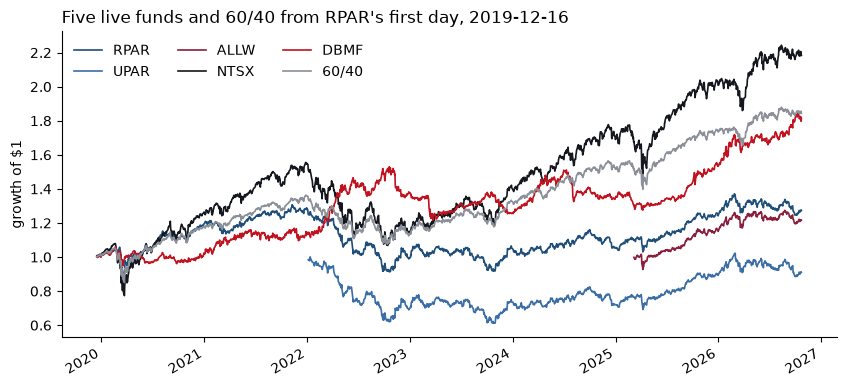

In [118]:
LIVE = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
returns['60/40'] = 0.6 * returns['SPY'] + 0.4 * returns['IEF']
returns['static four-way'] = 0.25 * (returns['SPY'] + returns['TLT'] + returns['GLD'] + returns['DBC'])

fig, ax = plt.subplots(figsize=(10, 4.5))
growth = (1 + returns.loc['2019-12-16':, LIVE + ['60/40']]).cumprod()
growth.plot(ax=ax, color=['#1f4e79', '#3b6ea5', '#8a1f3d', '#14181e', '#c1121f', '#8a8f98'], lw=1.2)
ax.set_ylabel('growth of $1'); ax.set_xlabel('')
ax.set_title('Five live funds and 60/40 from RPAR\'s first day, 2019-12-16', loc='left')
ax.legend(frameon=False, ncol=3); ax.spines[['top', 'right']].set_visible(False)
plt.show()


***


# 1. The Products


## 1.1

For `RPAR`, `UPAR`, `ALLW`, `NTSX`, `DBMF`, 60/40 and the static four-way, report over 2019-12-16 to 2026-10-23 and over 2022-01-05 to 2026-10-23:

* annualized mean and volatility, Sharpe ratio, skewness
* empirical 5% VaR and CVaR of daily returns
* maximum drawdown with its peak, trough and recovery dates
* calendar-year total returns for 2020 through 2026 to date, adding `SPY`, `TLT`, `TIP`, `GLD` and `DBC`

A fund that launched after a window opens starts later; mark it in the table.


In [119]:
FUNDS = LIVE + ["60/40", "static four-way"]

windows = {"2019-12-16 to 2026-10-23": returns.loc["2019-12-16":"2026-10-23"],
           "2022-01-05 to 2026-10-23": returns.loc["2022-01-05":"2026-10-23"]}

product_stats = {}

for window, df in windows.items():
    stats = project_utils.performance_stats(df[FUNDS], df["SHV"])

    #mark funds that launched after the window opens
    late = stats["First Return"] > df.index[0]
    stats.index = [f"{fund}*" if is_late else fund for fund, is_late in late.items()]

    product_stats[window] = stats

product_stats = pd.concat(product_stats, names = ["Window", "Fund"])

def format_date(x):
    return x.strftime("%Y-%m-%d") if pd.notna(x) else "Not recovered"

display(product_stats.style.format({"First Return": format_date,
                                    "Annualized Mean": "{:.2%}",
                                    "Annualized Volatility": "{:.2%}",
                                    "Sharpe Ratio": "{:.2f}",
                                    "Skewness": "{:.2f}",
                                    "VaR (0.05)": "{:.2%}",
                                    "CVaR (0.05)": "{:.2%}",
                                    "Max Drawdown": "{:.2%}",
                                    "Peak Date": format_date,
                                    "Trough Date": format_date,
                                    "Recovery Date": format_date})
                           .set_caption("* launched after the window opens; statistics start at its first return"))

In [120]:
calendar_cols = FUNDS + ["SPY", "TLT", "TIP", "GLD", "DBC"]

calendar_returns = project_utils.calendar_year_returns(returns.loc["2020-01-01":"2026-10-23", calendar_cols]).T
calendar_returns = calendar_returns.rename(columns = {2026: "2026 YTD"})

#flag partial years for funds that launched mid-year
first_returns = returns[calendar_cols].apply(pd.Series.first_valid_index)
year_starts = returns.loc["2020-01-01":].groupby(returns.loc["2020-01-01":].index.year).apply(lambda x: x.index[0])
partial_years = [f"{fund} {date.year} (from {date.date()})" for fund, date in first_returns.items()
                 if date.year in year_starts.index and date > year_starts[date.year]]

display(calendar_returns.style.format("{:.2%}", na_rep = "—")
                        .set_caption("Calendar-year total returns, 2020 through 2026-10-23"))

print("Partial years: " + "; ".join(partial_years))

Date,2020,2021,2022,2023,2024,2025,2026 YTD
RPAR,19.40%,7.55%,-22.80%,6.03%,0.07%,17.91%,2.53%
UPAR,—,—,-30.27%,5.73%,-2.24%,23.87%,2.06%
ALLW,—,—,—,—,—,15.08%,5.78%
NTSX,24.85%,22.20%,-25.84%,22.70%,20.20%,18.83%,8.71%
DBMF,1.80%,11.38%,21.53%,-8.94%,7.25%,13.84%,18.22%
60/40,16.94%,15.09%,-16.38%,16.98%,14.24%,14.32%,6.32%
static four-way,15.07%,14.49%,-8.29%,8.99%,11.08%,22.51%,12.54%
SPY,18.37%,28.75%,-18.17%,26.19%,24.89%,17.72%,12.32%
TLT,18.15%,-4.60%,-31.24%,2.77%,-8.06%,4.25%,-3.42%
TIP,10.84%,5.67%,-12.24%,3.81%,1.65%,6.77%,-0.03%


Partial years: UPAR 2022 (from 2022-01-05); ALLW 2025 (from 2025-03-07)


## 1.2

Regress `UPAR`'s daily excess return on `RPAR`'s over their common sample. Report

* the slope, the annualized intercept and $R^2$
* the ratio of `UPAR`'s volatility to `RPAR`'s and the ratio of the two maximum drawdowns over the same sample

The issuer describes `UPAR` as a more levered `RPAR`. What multiple do the data support, which of the statistics in 1.1 does it scale, and which does it leave where they were?


In [121]:
excess_returns = returns.sub(returns["SHV"], axis = 0)

#common sample of RPAR and UPAR
common = returns[["RPAR", "UPAR"]].dropna().index

upar_regression = project_utils.regression_stats(excess_returns.loc[common, "UPAR"], excess_returns.loc[common, "RPAR"])
upar_regression = upar_regression.rename({"RPAR": "Slope (beta on RPAR)", "Alpha": "Annualized Intercept"})

#compare the 1.1 statistics for both funds over the same sample
common_stats = project_utils.performance_stats(returns.loc[common, ["RPAR", "UPAR"]], returns.loc[common, "SHV"]).T
common_stats.loc["Annualized Excess Mean"] = excess_returns.loc[common, ["RPAR", "UPAR"]].mean() * 252

ratio_rows = ["Annualized Excess Mean", "Annualized Volatility", "Sharpe Ratio", "Skewness", "VaR (0.05)", "CVaR (0.05)", "Max Drawdown"]
common_stats = common_stats.loc[ratio_rows].astype(float)
common_stats["UPAR / RPAR"] = common_stats["UPAR"] / common_stats["RPAR"]

print(f"Common sample: {common[0].date()} to {common[-1].date()}, {len(common):,} days")

display(upar_regression.to_frame("UPAR on RPAR, daily excess returns")
                       .style.format("{:.4f}")
                       .format("{:.2%}", subset = (["Annualized Intercept", "Tracking Error"], slice(None))))

display(common_stats.style.format("{:.2%}")
                    .format("{:.2f}", subset = (["Sharpe Ratio", "Skewness"], slice(None)))
                    .format("{:.2f}", subset = "UPAR / RPAR")
                    .set_caption("RPAR and UPAR over the common sample"))

Common sample: 2022-01-05 to 2026-10-23, 1,205 days


,"UPAR on RPAR, daily excess returns"
Slope (beta on RPAR),1.2964
Annualized Intercept,-0.45%
Alpha t-stat,-0.1433
R-squared,0.8499
Tracking Error,6.87%


,RPAR,UPAR,UPAR / RPAR
Annualized Excess Mean,-2.80%,-4.09%,1.46
Annualized Volatility,12.68%,17.80%,1.40
Sharpe Ratio,-0.22,-0.23,1.04
Skewness,-0.01,0.10,-7.24
VaR (0.05),-1.33%,-1.79%,1.35
CVaR (0.05),-1.80%,-2.59%,1.44
Max Drawdown,-27.86%,-38.97%,1.40


In [122]:
#re-run the regression on non-overlapping multi-day excess returns to check whether daily timing noise attenuates the slope
horizons = {"1 day": 1, "2 days": 2, "5 days": 5, "21 days": 21}

horizon_regressions = {}

for label, days in horizons.items():
    summed = excess_returns.loc[common, ["RPAR", "UPAR"]].rolling(days).sum().iloc[days - 1::days]
    horizon_regressions[label] = project_utils.regression_stats(summed["UPAR"], summed["RPAR"], periods = 252 / days)

horizon_regressions = pd.DataFrame(horizon_regressions).T.rename(columns = {"RPAR": "Slope", "Alpha": "Annualized Intercept"})

display(horizon_regressions.style.format({"Slope": "{:.2f}",
                                          "Annualized Intercept": "{:.2%}",
                                          "Alpha t-stat": "{:.2f}",
                                          "R-squared": "{:.2f}",
                                          "Tracking Error": "{:.2%}"})
                           .set_caption("UPAR on RPAR by return horizon, non-overlapping excess returns"))

print(f"Correlation of UPAR with RPAR's previous-day excess return: {excess_returns.loc[common, 'UPAR'].corr(excess_returns.loc[common, 'RPAR'].shift(1)):.2f}")

,Slope,Annualized Intercept,Alpha t-stat,R-squared,Tracking Error
1 day,1.30,-0.45%,-0.14,0.85,6.87%
2 days,1.36,-0.30%,-0.15,0.94,4.40%
5 days,1.37,-0.24%,-0.14,0.95,3.76%
21 days,1.39,-0.24%,-0.32,0.99,1.63%


Correlation of UPAR with RPAR's previous-day excess return: 0.09


> **What multiple do the data support?** 
>> About 1.4. Over the common sample (2022-01-05 to 2026-10-23), `UPAR`'s volatility is 1.40 times `RPAR`'s and its maximum drawdown is 1.40 times as deep, consistent with the issuer's 1.4 times the RPAR Index exposures. The daily slope is lower, 1.30 with $R^2$ = 0.85, but that is attenuation from daily timing noise rather than a lower multiple: `UPAR` still co-moves with `RPAR`'s previous day (correlation 0.09), and on non-overlapping 2-, 5- and 21-day returns the slope rises to 1.36, 1.37 and 1.39 with $R^2$ reaching 0.99. The intercept, −0.45% a year with a $t$-statistic of −0.14, is not distinguishable from zero; its sign is consistent with `UPAR`'s 0.16% higher expense ratio and any financing cost on the extra exposure.
> 
> **Which statistics leverage scales.** 
>> Everything measured in units of return scales by roughly the multiple: the annualized excess mean (1.46×, more negative because `RPAR`'s excess return was negative), volatility (1.40×), VaR (1.35×), CVaR (1.44×) and maximum drawdown (1.40×).
> 
>**Which it leaves where they were.** 
>> Leverage changes scale, not shape or risk-adjusted return. The Sharpe ratio is unchanged (−0.22 against −0.23), and skewness stays close to zero for both. The drawdown peak is the same day for both funds (2022-01-12). But leverage does not simply scale the compounded path: `RPAR` bottomed on 2022-10-20, while `UPAR` kept falling to 2023-10-25 and recovered later (2026-02-23 against 2026-01-06), because volatility drag on a levered daily path compounds a negative excess return into a longer and deeper drawdown.

## 1.3

From Section 1 alone, write three claims an allocator could defend about how these products differ, each tied to a number in your tables, and name one claim about them you cannot test with these statistics.


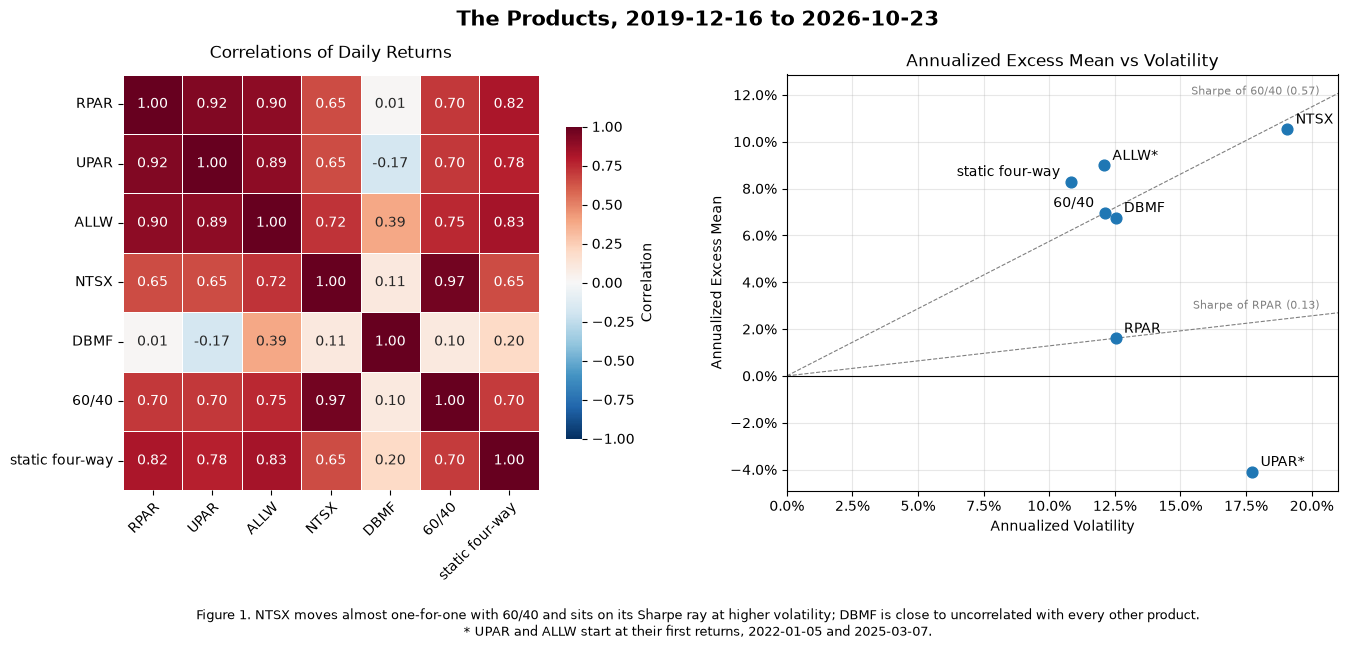

In [123]:
import seaborn as sns
from matplotlib.ticker import PercentFormatter

window_returns = returns.loc["2019-12-16":"2026-10-23", FUNDS]
window_excess = excess_returns.loc["2019-12-16":"2026-10-23", FUNDS]

fig, axes = plt.subplots(1, 2, figsize = (16, 6.5))

#pairwise correlations of daily returns, each pair over its common dates
sns.heatmap(window_returns.corr(), annot = True, fmt = ".2f", cmap = "RdBu_r", vmin = -1, vmax = 1, center = 0, square = True, linewidths = 0.5,
            cbar_kws = {"label": "Correlation", "shrink": 0.75}, ax = axes[0])
axes[0].set_title("Correlations of Daily Returns", fontsize = 12, pad = 12)
axes[0].tick_params(axis = "x", labelrotation = 45)
plt.setp(axes[0].get_xticklabels(), ha = "right", rotation_mode = "anchor")
axes[0].tick_params(axis = "y", labelrotation = 0)

#annualized excess mean against volatility; points on a ray from the origin share a Sharpe ratio
risk_return = pd.DataFrame({"Volatility": window_excess.std() * np.sqrt(252),
                            "Excess Mean": window_excess.mean() * 252})

ax = axes[1]
ax.scatter(risk_return["Volatility"], risk_return["Excess Mean"], s = 60, zorder = 3)

#place labels left of the points that sit close together
left_labels = ["60/40", "static four-way"]

for fund, row in risk_return.iterrows():
    label = f"{fund}*" if fund in ["UPAR", "ALLW"] else fund
    ax.annotate(label, (row["Volatility"], row["Excess Mean"]), xytext = (-8, 4) if fund in left_labels else (6, 4),
                textcoords = "offset points", ha = "right" if fund in left_labels else "left")

vol_grid = np.linspace(0, 0.21, 50)
for fund in ["60/40", "RPAR"]:
    sharpe = risk_return.loc[fund, "Excess Mean"] / risk_return.loc[fund, "Volatility"]
    ax.plot(vol_grid, sharpe * vol_grid, linestyle = "--", linewidth = 0.8, color = "gray")
    ax.annotate(f"Sharpe of {fund} ({sharpe:.2f})", (0.205, sharpe * 0.205), xytext = (-4, 4), textcoords = "offset points", ha = "right", fontsize = 8, color = "gray")

ax.set(title = "Annualized Excess Mean vs Volatility", xlabel = "Annualized Volatility", ylabel = "Annualized Excess Mean", xlim = (0, 0.21))
ax.axhline(0, color = "black", linewidth = 0.8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha = 0.3)

fig.suptitle("The Products, 2019-12-16 to 2026-10-23", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 1. NTSX moves almost one-for-one with 60/40 and sits on its Sharpe ray at higher volatility; DBMF is close to uncorrelated with every other product.\n"
         "* UPAR and ALLW start at their first returns, 2022-01-05 and 2025-03-07.", ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.24, wspace = 0.25)
plt.show()

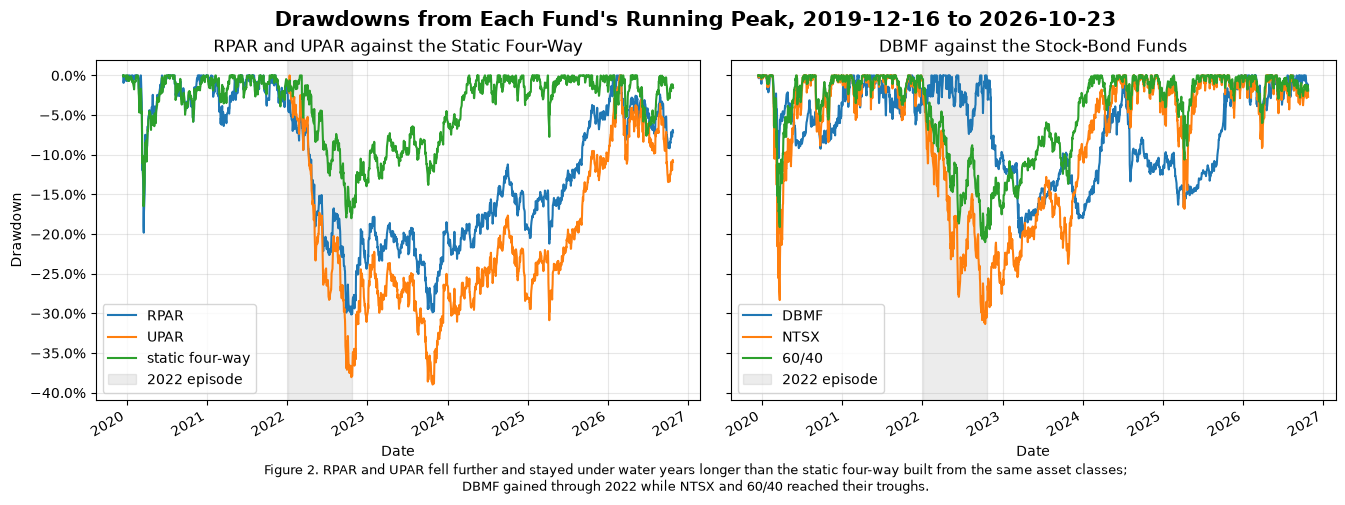

In [124]:
def drawdown_path(returns):
    wealth = (1 + returns.dropna()).cumprod()
    return wealth / wealth.cummax().clip(lower = 1) - 1

fig, axes = plt.subplots(1, 2, figsize = (16, 5), sharey = True)

panels = {"RPAR and UPAR against the Static Four-Way": ["RPAR", "UPAR", "static four-way"],
          "DBMF against the Stock-Bond Funds": ["DBMF", "NTSX", "60/40"]}

for ax, (title, funds) in zip(axes, panels.items()):
    window_returns[funds].apply(drawdown_path).plot(ax = ax, linewidth = 1.5)

    ax.set(title = title, xlabel = "Date", ylabel = "Drawdown")
    ax.axvspan(pd.Timestamp("2022-01-03"), pd.Timestamp("2022-10-24"), color = "gray", alpha = 0.15, label = "2022 episode")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(loc = "lower left")
    ax.grid(alpha = 0.3)

fig.suptitle("Drawdowns from Each Fund's Running Peak, 2019-12-16 to 2026-10-23", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 2. RPAR and UPAR fell further and stayed under water years longer than the static four-way built from the same asset classes;\n"
         "DBMF gained through 2022 while NTSX and 60/40 reached their troughs.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.2, wspace = 0.05)
plt.show()

> **Claim 1: `NTSX` is a levered 60/40, not a different strategy.** 
>>Its daily returns correlate 0.97 with 60/40 (Figure 1), and its volatility is 19.1% against 60/40's 12.1%, about 1.6 times, while its Sharpe ratio is 0.55 against 0.57. As with `UPAR` and `RPAR` in 1.2, the leverage raised the mean (13.3% vs 9.7%), VaR (−1.80% vs −1.11%) and maximum drawdown (−31.3% vs −21.0%) and left the Sharpe ratio where it was. An allocator buying `NTSX` buys 60/40 risk at a higher dose, not a different risk.
> 
> **Claim 2: `DBMF` is the only product here that diversified the others.** 
>>Its daily correlation is 0.01 with `RPAR` and 0.10 with 60/40 (Figure 1). In 2022 it returned +21.5% while `RPAR` lost 22.8%, `UPAR` 30.3%, `NTSX` 25.8% and 60/40 16.4%, and its maximum drawdown began on 2022-10-20, the day `RPAR` and the static four-way reached their troughs (Figure 2). The case for it is what it does in a portfolio, not its standalone record: its Sharpe ratio of 0.54 is below 60/40's, and its skewness of −0.60 is the most negative of the seven.
> 
> **Claim 3: `RPAR` lagged a naive equal-weight portfolio of broadly the same asset classes.** 
>>Over 2019-12-16 to 2026-10-23 the static four-way had a Sharpe ratio of 0.77 against `RPAR`'s 0.13, lower volatility (10.8% vs 12.6%) and a shallower maximum drawdown (−18.0% vs −30.1%), and it recovered in April 2024, almost two years before `RPAR` did in January 2026 (Figure 2). `RPAR` beat it only in 2020 (+19.4% vs +15.1%); the widest gap was 2022 (−22.8% vs −8.3%). The two correlate 0.82, so they share most of their exposures; what `RPAR` does differently cost about 6.7% a year of excess return over this window. This is one seven-year record with one rate shock, so it judges `RPAR`'s implementation over this period, not the risk-parity rule (Section 4).
> 
> **A claim these statistics cannot test: `RPAR` balances risk across its four asset classes, "each at 25% of target risk."** 
>> Every number in Section 1 comes from the fund's total return, so it shows how much risk `RPAR` carried and when it lost money, but not where the risk came from. Testing the claim needs the fund's exposures, from the factor decomposition in Section 2 or the issuer's holdings, and the risk contributions $w_i(\Sigma\boldsymbol{w})_i$ computed from them. A related caution: `ALLW`'s Sharpe ratio of 0.74 rests on 1.6 years of returns, and its standard error is roughly $\sqrt{1/1.6} \approx 0.78$, so Section 1 cannot tell it apart from zero.

***


# 2. What They Hold

Sections 2 and 3 use excess returns over `SHV`.


## 2.1

Choose the factor set for the decompositions from `SPY`, `TLT`, `IEF`, `TIP`, `GLD` and `DBC`. State it and justify it in course terms, including whether both Treasury ETFs belong in one regression. Use the same set through Sections 2 and 3 unless a question asks otherwise.


In [125]:
FACTOR_MENU = ["SPY", "TLT", "IEF", "TIP", "GLD", "DBC"]
FACTORS = ["SPY", "TLT", "TIP", "GLD", "DBC"]

menu_excess = excess_returns[FACTOR_MENU].dropna()

factor_samples = {f"{menu_excess.index[0].date()} to {menu_excess.index[-1].date()}": menu_excess,
                  "RPAR's life": menu_excess.loc["2019-12-16":]}

#correlations of daily excess returns across the six candidate factors
factor_corr = pd.concat({sample: df.corr() for sample, df in factor_samples.items()}, axis = 1)

display(factor_corr.style.format("{:.2f}")
                   .background_gradient(cmap = "RdBu_r", vmin = -1, vmax = 1)
                   .set_caption("Correlations of daily excess returns over SHV"))

#variance inflation factors with both Treasury ETFs and with one dropped
menus = {"All six factors": FACTOR_MENU,
         "Without IEF": FACTORS,
         "Without TLT": ["SPY", "IEF", "TIP", "GLD", "DBC"]}

factor_vif = pd.concat({sample: pd.DataFrame({menu: project_utils.variance_inflation(df[cols]) for menu, cols in menus.items()})
                        for sample, df in factor_samples.items()}, axis = 1).loc[FACTOR_MENU]

display(factor_vif.style.format("{:.1f}", na_rep = "—")
                  .set_caption("Variance inflation factors, 1 / (1 - R-squared) of each factor on the others"))

In [126]:
#each fund's full-life daily regression under the three menus
menu_comparison = {}

for fund in LIVE:
    for menu, cols in menus.items():
        stats = project_utils.regression_stats(excess_returns[fund], excess_returns[cols])
        stats["Sum of Betas"] = stats[cols].sum()
        menu_comparison[(fund, menu)] = stats

menu_comparison = pd.DataFrame(menu_comparison).T[["TLT", "IEF", "TIP", "Sum of Betas", "R-squared"]]
menu_comparison.index.names = ["Fund", "Menu"]

display(menu_comparison.style.format("{:.2f}", na_rep = "—")
                       .format("{:.3f}", subset = "R-squared")
                       .set_caption("Treasury and TIPS betas, sum of betas and R-squared by factor menu, daily excess returns over each fund's life"))

> **Factor set: `SPY`, `TLT`, `TIP`, `GLD`, `DBC`, with `IEF` dropped** 
>> A factor decomposition needs regressors that each stand for a distinct, investable source of risk. Correlated regressors do not bias the fit, but they inflate the standard errors of the individual betas, so the regression can no longer say which exposure a fund holds. The five chosen ETFs are each a separate asset class these funds say they hold: equities (`SPY`), nominal Treasuries (`TLT`), inflation-linked bonds (`TIP`), gold (`GLD`) and broad commodities (`DBC`). They line up with `RPAR`'s index sleeves (global equities, Treasuries, TIPS, commodities) and with `ALLW`'s stated mandate (stocks, nominal bonds, inflation-linked bonds, commodities). They are also the five assets the risk-parity portfolios of Section 4 hold, so the betas here and the ERC weights in 4.4 are in the same units. Every variance inflation factor in the five-factor set is 2.5 or below.
>> * **`TIP` stays despite a 0.70 correlation with `TLT`.** `TIP`'s return combines real-rate duration with breakeven inflation, and the part not explained by `TLT` is the inflation exposure, the largest sleeve of `RPAR`'s index (35%). Its VIF is 2.2 to 2.5, and `RPAR`'s `TIP` beta (0.54) is well identified.
>>
>> * **`GLD` and `DBC` stay together.** They correlate only 0.28 to 0.34, and they behaved differently when it mattered: `DBC` returned +19.3% in 2022 when `GLD` returned −0.8%, and `GLD` returned +63.7% in 2025 against `DBC`'s +8.1%.
> 
> **Should both Treasury ETFs be in one regression? No.** 
>> * **They are the same factor at two durations.** `TLT` and `IEF` correlate 0.91 over both samples. With both in, their VIFs rise from about 2.5 to 3 to 6 to 7, so the standard error of each Treasury beta grows by roughly $\sqrt{6/2.4} \approx 1.6$.
>>
>> * **The second one adds no fit for the risk-parity funds.** With `TLT` already in, `RPAR`'s `IEF` beta is −0.00 and $R^2$ stays 0.865; `UPAR`'s $R^2$ stays 0.795.
>>
>> * **Where both get weight, the regression builds an offsetting long-short.** `DBMF` loads +0.32 on `TLT` and −1.33 on `IEF`, and its sum of betas moves from 0.00 to −0.55. That is a curve position fitted from the small differences between two nearly collinear series; it would be unstable in the rolling windows of 2.3 and would make the replicas in 3.1 take offsetting positions.
> 
> **Why `TLT` rather than `IEF`:** 
>> `TLT` fits the risk-parity funds better: $R^2$ of 0.865 against 0.839 for `RPAR` and 0.795 against 0.759 for `UPAR`, with `ALLW` about the same. It is also the long Treasury in the static four-way and in Section 4. The cost falls on two funds. `NTSX`, whose Treasury sleeve targets 3- to 8-year duration, fits slightly better with `IEF` (0.933 against 0.928). `DBMF` also fits better with `IEF` (0.211 against 0.158), but its $R^2$ stays below 0.24 under every menu, so its shortfall is a missing factor (trend-following across futures, taken up in 3.2), not a choice of Treasury ETF.
> 
> **Caveat for 2.4:** 
>> The Treasury choice changes the sum of betas. `IEF` has less than half of `TLT`'s volatility (6.8% against 15.0% a year), so the same bond exposure takes a larger `IEF` beta: `RPAR`'s sum of betas is 1.39 with `TLT` and 1.70 with `IEF`.

## 2.2

Regress each of `RPAR`, `UPAR`, `ALLW`, `NTSX` and `DBMF` on your factor set over its full life, once with daily and once with monthly returns. Report

* the betas and their sum
* the annualized intercept with its $t$-statistic
* $R^2$ and the annualized tracking error


In [127]:
monthly_excess = monthly.sub(monthly["SHV"], axis = 0)

frequencies = {"Daily": (excess_returns, 252), "Monthly": (monthly_excess, 12)}

factor_regressions = {}

for frequency, (df, periods) in frequencies.items():
    for fund in LIVE:
        sample = df[[fund] + FACTORS].dropna()

        stats = project_utils.regression_stats(sample[fund], sample[FACTORS], periods = periods)
        stats["Sum of Betas"] = stats[FACTORS].sum()
        stats["Start"] = sample.index[0].strftime("%Y-%m-%d")
        stats["Observations"] = len(sample)

        factor_regressions[(frequency, fund)] = stats

factor_regressions = pd.DataFrame(factor_regressions).T
factor_regressions = factor_regressions[FACTORS + ["Sum of Betas", "Alpha", "Alpha t-stat", "R-squared", "Tracking Error", "Start", "Observations"]]
factor_regressions = factor_regressions.rename(columns = {"Alpha": "Annualized Intercept", "Tracking Error": "Annualized Tracking Error"})
factor_regressions.index.names = ["Frequency", "Fund"]

display(factor_regressions.style.format("{:.2f}", subset = FACTORS + ["Sum of Betas", "Alpha t-stat", "R-squared"])
                          .format("{:.2%}", subset = ["Annualized Intercept", "Annualized Tracking Error"])
                          .format("{:,.0f}", subset = "Observations")
                          .set_caption("Full-life regressions of fund excess returns on SPY, TLT, TIP, GLD and DBC excess returns over SHV"))

> **Notes on the table:** 
> * **Monthly betas are larger than daily for the risk-parity funds.** `RPAR`'s sum of betas is 1.39 daily and 1.53 monthly, `UPAR`'s 1.76 and 2.04, and `ALLW`'s 1.68 and 1.82; $R^2$ rises from 0.79–0.88 to 0.95–0.99. As with `UPAR` on `RPAR` in 1.2, differences in closing times between the funds and the factor ETFs attenuate daily betas, and the attenuation fades as returns are summed over a month.
> 
> * **`RPAR` has a negative intercept at both frequencies.** −3.55% a year daily ($t$ = −2.01) and −3.00% monthly ($t$ = −2.30), well beyond its 0.52% expense ratio. It is the only fund whose intercept is significant on a sample of reasonable length; 3.3 takes up where it comes from.
> 
> * **`ALLW`'s monthly regression rests on 18 months for six parameters.** Its 5.17% intercept with $t$ = 3.17 and $R^2$ of 0.99 should not be read as evidence of skill; the daily regression on 411 days puts the intercept at −0.25% with $t$ = −0.08.
> 
> * **`DBMF` is not explained by a fixed mix of these factors** ($R^2$ of 0.16 daily and 0.17 monthly, tracking error above 10%). Its betas sum to about zero daily, consistent with a long-short futures book whose exposures change over time (2.3, 3.2).

## 2.3

Repeat the daily regression on a trailing 252-day window, stepped forward 21 trading days at a time.

* Plot each fund's betas, $R^2$ and sum of betas through time, and report the range of each.


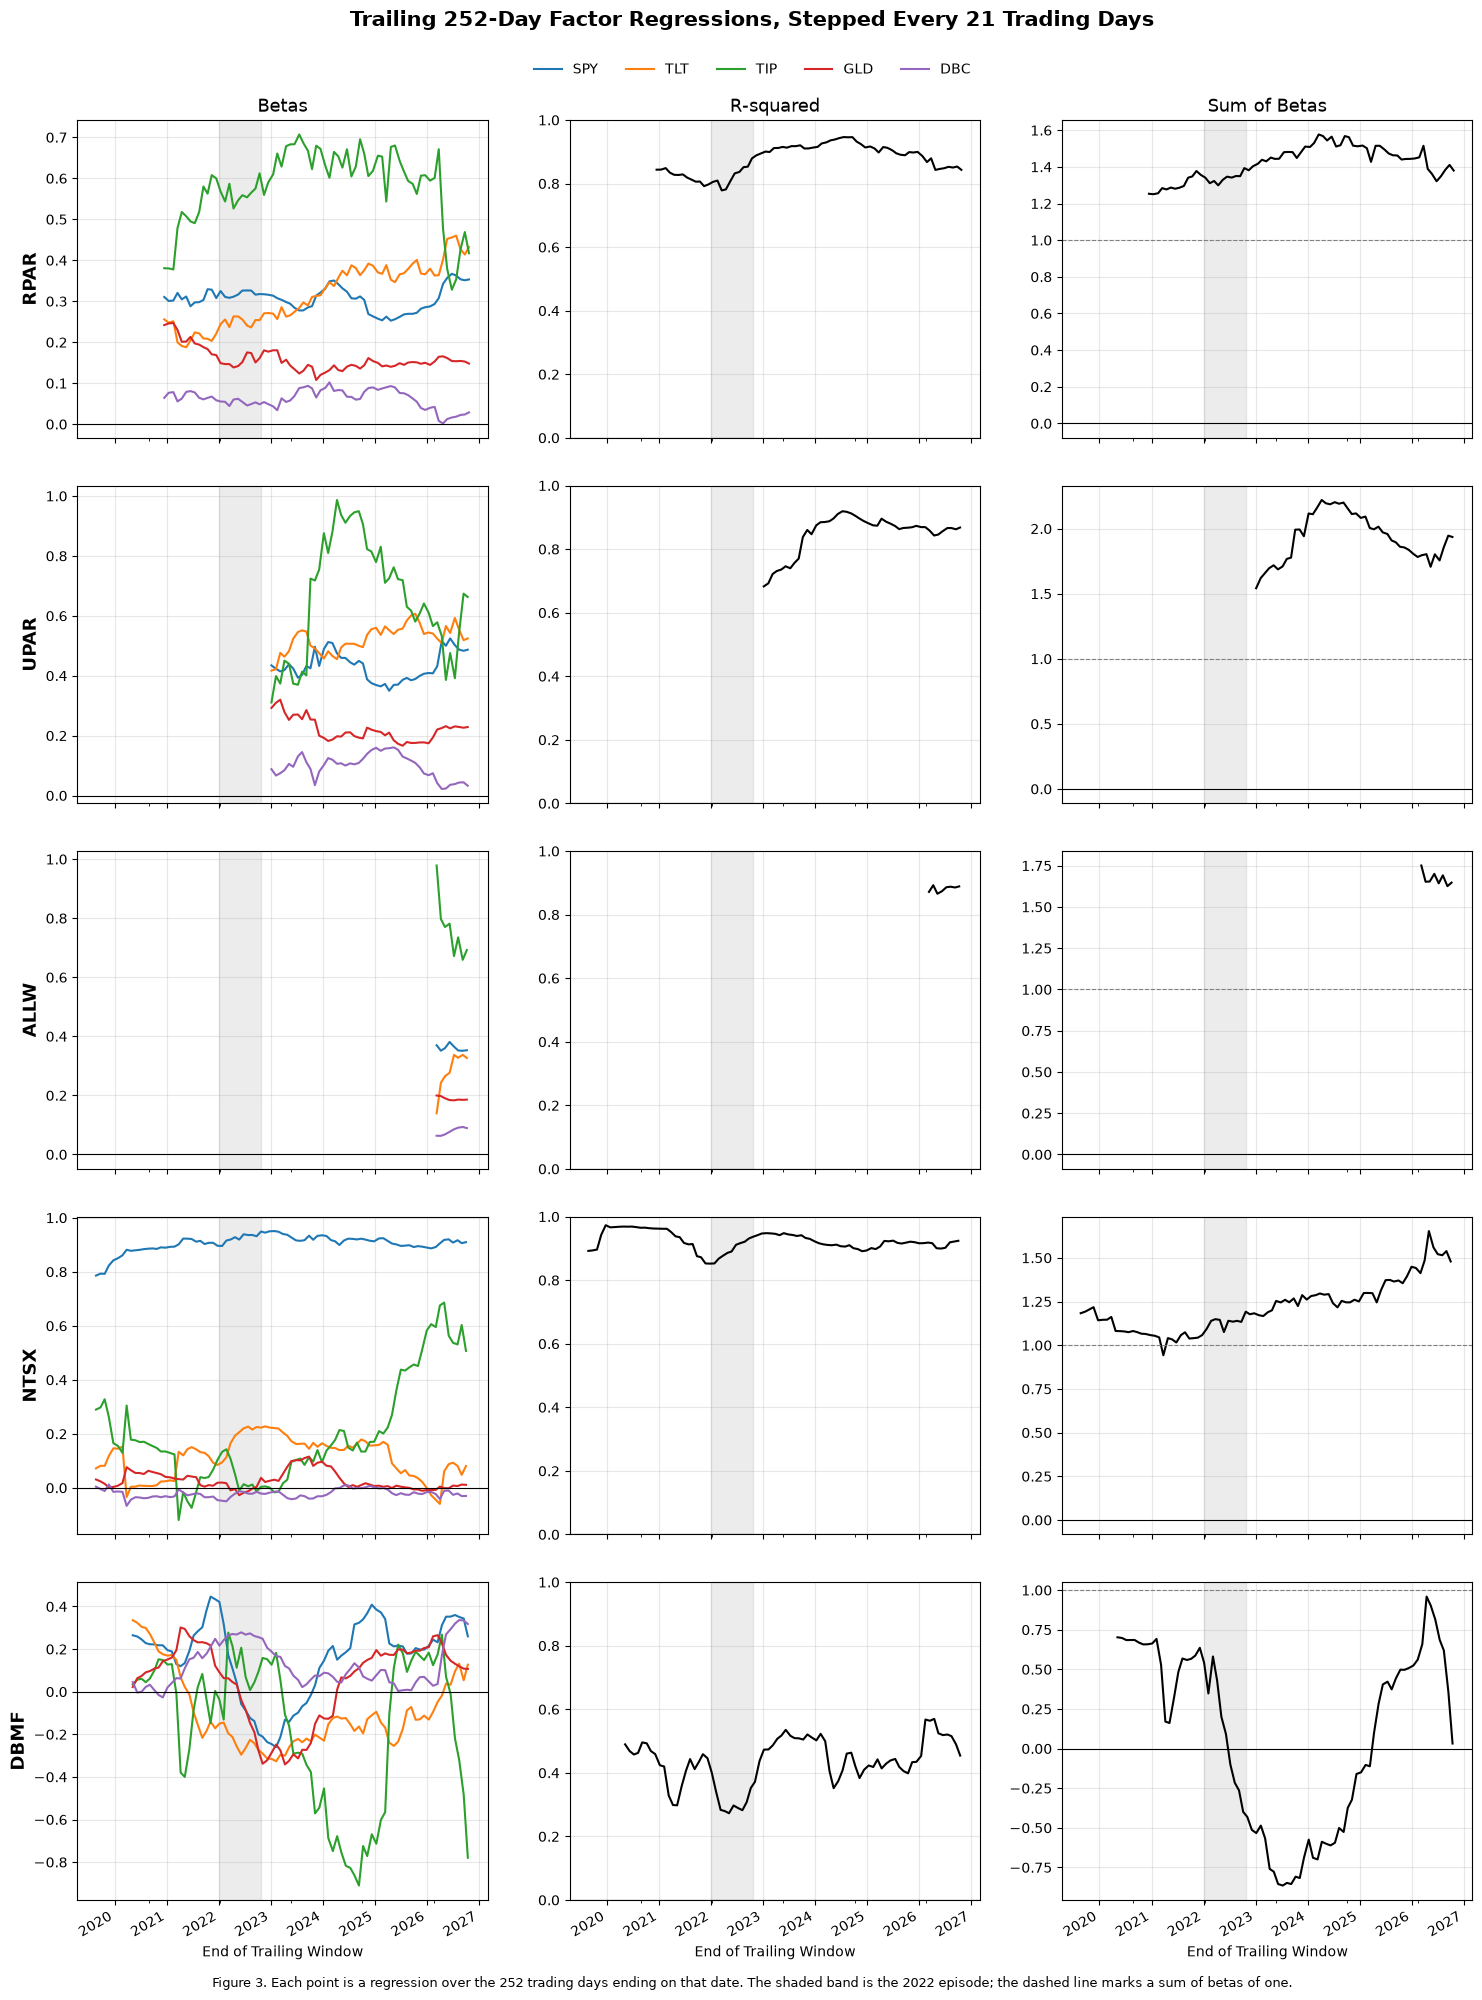

In [128]:
#trailing 252-day daily regressions, stepped forward 21 trading days at a time
rolling_betas = {fund: project_utils.rolling_regression(excess_returns[fund], excess_returns[FACTORS]) for fund in LIVE}

fig, axes = plt.subplots(len(LIVE), 3, figsize = (18, 4 * len(LIVE)), sharex = True)

for row, fund in zip(axes, LIVE):
    rolling = rolling_betas[fund]

    rolling[FACTORS].plot(ax = row[0], linewidth = 1.5, legend = False)
    rolling["R-squared"].plot(ax = row[1], linewidth = 1.5, color = "black")
    rolling["Sum of Betas"].plot(ax = row[2], linewidth = 1.5, color = "black")

    row[0].set_ylabel(fund, fontsize = 13, fontweight = "bold")
    row[1].set_ylim(0, 1)
    row[2].axhline(1, color = "gray", linestyle = "--", linewidth = 0.8)

    for ax in row:
        ax.axhline(0, color = "black", linewidth = 0.8)
        ax.axvspan(pd.Timestamp("2022-01-03"), pd.Timestamp("2022-10-24"), color = "gray", alpha = 0.15)
        ax.set_xlabel("End of Trailing Window")
        ax.grid(alpha = 0.3)

for ax, title in zip(axes[0], ["Betas", "R-squared", "Sum of Betas"]):
    ax.set_title(title, fontsize = 13)

fig.legend(FACTORS, loc = "upper center", ncol = len(FACTORS), bbox_to_anchor = (0.5, 0.975), frameon = False)
fig.suptitle("Trailing 252-Day Factor Regressions, Stepped Every 21 Trading Days", fontsize = 15, fontweight = "bold", y = 0.995)

fig.text(0.5, 0.005, "Figure 3. Each point is a regression over the 252 trading days ending on that date. The shaded band is the 2022 episode; the dashed line marks a sum of betas of one.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(top = 0.94, bottom = 0.05, hspace = 0.15, wspace = 0.2)
plt.show()

> The trailing 252-day regressions reveal substantial differences in the stability of factor exposures across funds. RPAR, UPAR, and NTSX maintain relatively high (R^2) values, suggesting that our five-factor model consistently captures much of their return variation, despite changes in individual factor loadings. 
> 
> In contrast, DBMF exhibits frequent sign reversals in its betas and more variable explanatory power, consistent with its dynamic managed-futures strategy. The sum of betas also varies across funds and over time, reflecting changes in aggregate fitted factor sensitivities rather than necessarily changes in actual leverage. 
>
> Finally, the shorter histories of UPAR and particularly ALLW limit the number of available rolling windows, making comparisons of exposure stability across funds less direct. The following table summarizes the minimum and maximum values of each rolling statistic.

In [129]:
#range of each rolling statistic across windows
range_cols = FACTORS + ["Sum of Betas", "R-squared"]

rolling_range = pd.DataFrame({fund: rolling[range_cols].agg(["min", "max"]).unstack() for fund, rolling in rolling_betas.items()}).T
rolling_range["Windows"] = pd.Series({fund: len(rolling) for fund, rolling in rolling_betas.items()})

display(rolling_range.style.format("{:.2f}")
                     .format("{:,.0f}", subset = "Windows")
                     .set_caption("Range of trailing 252-day betas, sum of betas and R-squared across windows"))

> **Notes on the rolling regressions:**
>
> * **`RPAR`:** Factor exposures drift over time but remain relatively stable, with the sum of betas consistently above one (1.25–1.58) and $R^2$ ranging from 0.78 to 0.95. Within its fixed-income exposures, `TLT` and `TIP` betas move in opposite directions during parts of 2026. Given their correlation of approximately 0.70, this may reflect the regression reallocating explanatory power between correlated factors rather than substantial changes in the underlying holdings.
>
> * **`UPAR`:** `UPAR` exhibits the highest aggregate factor exposure, with the sum of betas ranging from 1.54 to 2.22, consistent with its more leveraged risk-parity strategy. Its $R^2$ increases from approximately 0.68 in the earliest window to 0.84–0.87 in later windows, suggesting that the five-factor model explains its returns more effectively over time. However, its relatively large variation in `TIP` exposure (0.31–0.99) indicates that its factor sensitivities are not constant.
>
> * **`NTSX`:** `NTSX` maintains the most stable equity exposure, with `SPY` beta ranging from 0.79 to 0.95 and consistently high $R^2$ (0.85–0.97). However, its fixed-income sensitivities shift substantially, particularly as `TIP` beta rises to 0.69 while `TLT` exposure remains near zero in later windows. This may reflect differences between the duration profile of `NTSX`'s Treasury futures and the longer-duration `TLT` benchmark, as well as overlapping explanatory power between Treasury factors. Its sum of betas consequently varies from 0.94 to 1.65.
>
> * **`DBMF`:** `DBMF` exhibits the greatest instability in factor exposures, with every beta changing sign across rolling windows and the sum of betas ranging from −0.86 to 0.96. Its rolling $R^2$ (0.27–0.57) is substantially higher than its full-sample $R^2$ of approximately 0.16, suggesting that the factors explain its returns better over shorter horizons than with fixed full-sample coefficients. This is consistent with `DBMF`'s dynamic managed-futures strategy, where changing long and short positions make a static factor decomposition less effective.
>
> * **`ALLW`:** `ALLW` has only eight rolling windows, limiting our ability to assess the persistence of its exposures. Its `TIP` beta is relatively large (0.66–0.98), and its $R^2$ remains high (0.87–0.89), indicating a strong fit over the available period. However, its short return history makes broader conclusions about exposure stability premature.

## 2.4

State what the sum of betas measures for these funds and how it depends on the choice in 2.1. Show the dependence for one fund by re-running 2.2 under a different menu.


In [130]:
#re-run the 2.2 regressions for RPAR under alternative factor menus
alt_menus = {"Chosen (SPY, TLT, TIP, GLD, DBC)": FACTORS,
             "IEF in place of TLT": ["SPY", "IEF", "TIP", "GLD", "DBC"],
             "Both Treasuries": FACTOR_MENU,
             "Without TIP": ["SPY", "TLT", "GLD", "DBC"]}

menu_sensitivity = {}

for frequency, (df, periods) in frequencies.items():
    sample = df[["RPAR"] + FACTOR_MENU].dropna()
    factor_vol = sample[FACTOR_MENU].std() * np.sqrt(periods)

    for menu, cols in alt_menus.items():
        stats = project_utils.regression_stats(sample["RPAR"], sample[cols], periods = periods)
        stats["Sum of Betas"] = stats[cols].sum()
        #each beta times its factor's volatility: the fund's volatility exposure to each factor, summed
        stats["Sum of Beta x Factor Vol"] = (stats[cols] * factor_vol[cols]).sum()
        menu_sensitivity[(frequency, menu)] = stats

menu_sensitivity = pd.DataFrame(menu_sensitivity).T
menu_sensitivity = menu_sensitivity[FACTOR_MENU + ["Sum of Betas", "Sum of Beta x Factor Vol", "Alpha", "Alpha t-stat", "R-squared", "Tracking Error"]]
menu_sensitivity = menu_sensitivity.rename(columns = {"Alpha": "Annualized Intercept", "Tracking Error": "Annualized Tracking Error"})
menu_sensitivity.index.names = ["Frequency", "Menu"]

display(menu_sensitivity.style.format("{:.2f}", na_rep = "—")
                        .format("{:.2%}", subset = ["Sum of Beta x Factor Vol", "Annualized Intercept", "Annualized Tracking Error"])
                        .set_caption("RPAR's full-life regression under four factor menus"))

> **What the sum of betas measures**
>
> Since each regression uses excess returns over `SHV`, the factor betas represent the fitted dollar exposure to each factor ETF per dollar of fund NAV, assuming the remaining position is financed through the cash benchmark. The sum of betas therefore measures aggregate **net fitted factor exposure**, rather than actual gross leverage.
>
> For example, `RPAR` has a sum of betas of 1.39 daily (1.53 monthly), implying approximately $1.39 of net factor exposure per dollar of NAV under the chosen factor menu. `UPAR` has a larger sum of 1.76 daily (2.04 monthly), consistent with its more leveraged strategy. Conversely, `DBMF` has a daily sum near zero (0.00), but this does not imply an absence of exposure: positive and negative factor sensitivities can offset, consistent with its rolling sum ranging from −0.86 to 0.96 in Section 2.3.
>
> **Dependence on factor selection (Question 2.1)**
>
> The sum of betas depends on the factor ETFs used because each beta measures exposure in units of its corresponding ETF. A less volatile ETF generally requires a larger beta to capture a comparable return sensitivity. Re-estimating `RPAR` under four factor menus illustrates this dependence:
>
> - **Replacing `TLT` with `IEF`:** The daily Treasury beta increases from 0.30 to 0.56, while the sum of betas rises from 1.39 to 1.70 (1.53 to 1.81 monthly). Because `IEF` has lower duration and volatility than `TLT`, a larger beta is needed to capture comparable interest-rate sensitivity.
> - **Excluding `TIP`:** The daily `TLT` beta increases from 0.30 to 0.46 as some previously explained variation is absorbed by the remaining factors. However, the sum of betas falls from 1.39 to 1.08 (1.53 to 1.22 monthly), demonstrating that the aggregate beta depends on how the underlying exposures are represented.
> - **Including both `TLT` and `IEF`:** For `RPAR`, the additional `IEF` beta is approximately zero, leaving the sum of betas and $R^2$ nearly unchanged. However, the earlier results for `DBMF` show that including both can produce offsetting Treasury betas and materially alter the sum, illustrating the potential instability introduced by correlated regressors.
>
> Despite these differences, the overall regression fit changes relatively little. Across the four menus, `RPAR`'s daily sum of betas ranges from 1.08 to 1.70, while $R^2$ remains between 0.83 and 0.86. Similarly, the sum of beta-weighted factor volatilities stays relatively stable at approximately 18.0%–19.5%, suggesting that the underlying fitted risk exposure is less sensitive to factor selection than the unweighted sum of betas.
>
> **Overall, the sum of betas is useful for comparing fitted exposures under a common factor specification, but it should not be interpreted as a direct measure of a fund's actual leverage.** For example, `NTSX` targets 150% notional exposure (90% equities and 60% Treasury futures), yet its fitted sum is 1.18 using `TLT` and 1.36 using `IEF`. This difference reflects the choice of factor proxies rather than necessarily a change in the fund's underlying positions.

***


# 3. Replication


## 3.1

Replicate each fund out of sample in the ProShares manner: fit on a trailing 252-day window, apply the fit to the next 21 trading days, roll forward. Build two replicas: one fitted with an intercept, which the replica keeps, and one fitted without an intercept. For each fund and each replica report

* the out-of-sample correlation and tracking error
* the annualized mean of the target beside the replica's


In [131]:
#fit on the trailing 252 days, hold the fit for the next 21, roll forward
replicas = {(fund, label): project_utils.oos_replication(excess_returns[fund], excess_returns[FACTORS], intercept = intercept)
            for fund in LIVE for label, intercept in [("With intercept", True), ("No intercept", False)]}

replication_stats = {}

for (fund, label), replica in replicas.items():
    target = excess_returns.loc[replica.index, fund]

    replication_stats[(fund, label)] = {"Start": replica.index[0].strftime("%Y-%m-%d"),
                                        "Days": len(replica),
                                        "Correlation": target.corr(replica),
                                        "Tracking Error": (target - replica).std() * np.sqrt(252),
                                        "Target Mean": target.mean() * 252,
                                        "Replica Mean": replica.mean() * 252}

replication_stats = pd.DataFrame(replication_stats).T
replication_stats["Mean Gap"] = replication_stats["Target Mean"] - replication_stats["Replica Mean"]
replication_stats.index.names = ["Fund", "Replica"]

display(replication_stats.style.format({"Days": "{:,.0f}",
                                        "Correlation": "{:.2f}",
                                        "Tracking Error": "{:.2%}",
                                        "Target Mean": "{:.2%}",
                                        "Replica Mean": "{:.2%}",
                                        "Mean Gap": "{:.2%}"})
                             .set_caption("Out-of-sample replication on SPY, TLT, TIP, GLD and DBC, daily excess returns; means and tracking error annualized"))

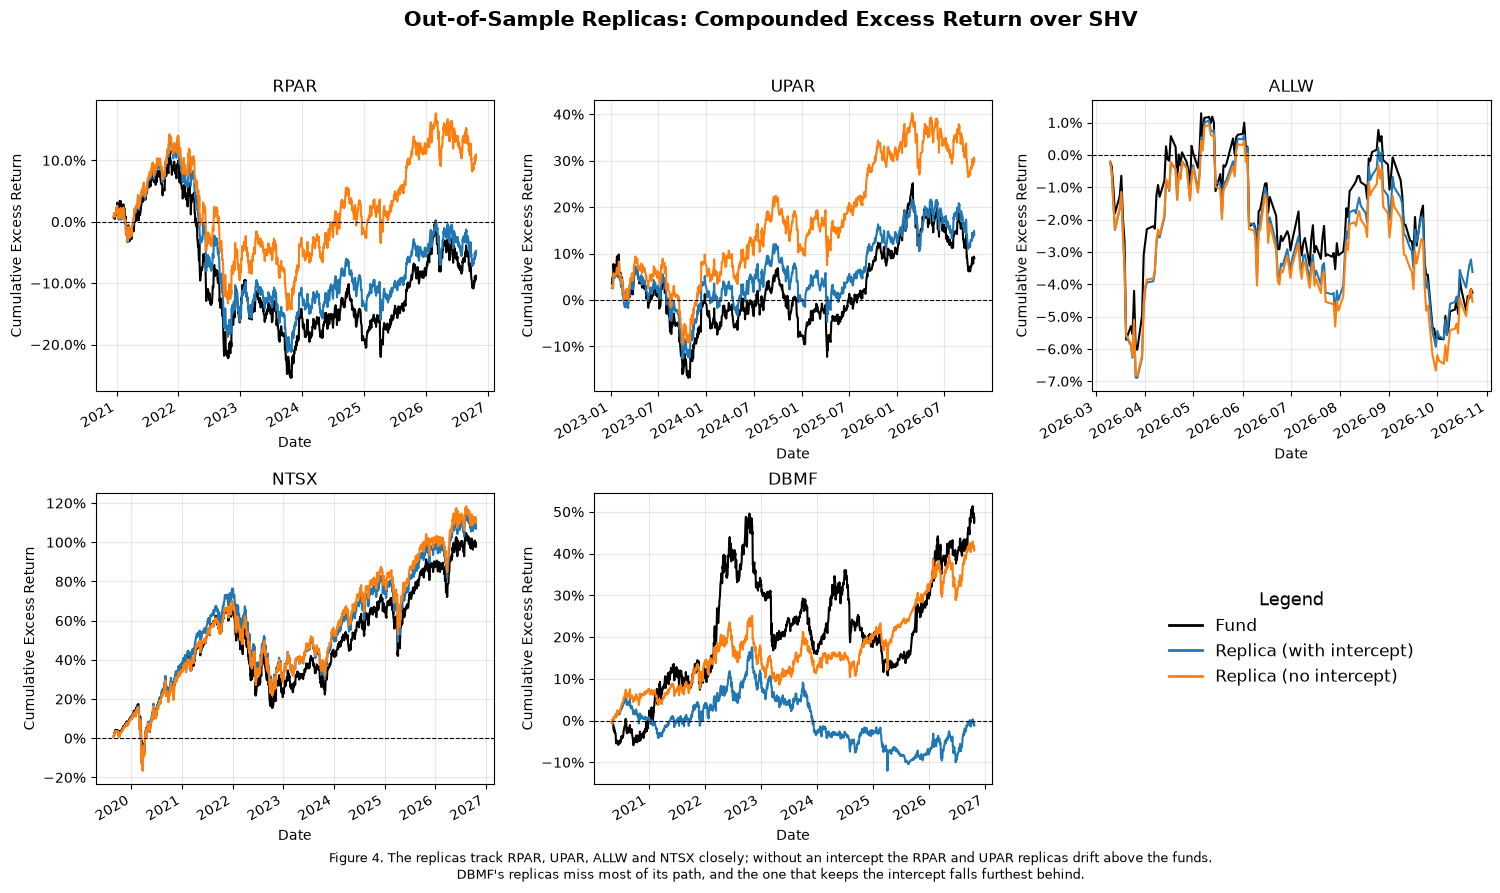

In [132]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(2, 3, figsize = (18, 9))

for ax, fund in zip(axes.flat, LIVE):
    replica_index = replicas[(fund, "With intercept")].index

    cumulative = pd.DataFrame({"Fund": excess_returns.loc[replica_index, fund],
                               "With intercept": replicas[(fund, "With intercept")],
                               "No intercept": replicas[(fund, "No intercept")]})
                               
    cumulative = (1 + cumulative).cumprod() - 1

    cumulative.plot(ax = ax, linewidth = 1.5, color = ["black", "tab:blue", "tab:orange"], legend = False)

    ax.set(title = fund, xlabel = "Date", ylabel = "Cumulative Excess Return")
    ax.axhline(0, color = "black", linestyle = "--", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha = 0.3)

legend_ax = axes.flat[-1]
legend_ax.axis("off")
legend_handles = [Line2D([0], [0], color = "black", lw = 2, label = "Fund"),
                  Line2D([0], [0], color = "tab:blue", lw = 2, label = "Replica (with intercept)"),
                  Line2D([0], [0], color = "tab:orange", lw = 2, label = "Replica (no intercept)")]
legend_ax.legend(handles = legend_handles, loc = "center", frameon = False, fontsize = 12, title = "Legend", title_fontsize = 13)

fig.suptitle("Out-of-Sample Replicas: Compounded Excess Return over SHV", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 4. The replicas track RPAR, UPAR, ALLW and NTSX closely; without an intercept the RPAR and UPAR replicas drift above the funds.\n"
         "DBMF's replicas miss most of its path, and the one that keeps the intercept falls furthest behind.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.12, hspace = 0.35, wspace = 0.25)
plt.show()

> **Notes on the replicas**
>
> * **The intercept moves the mean, not the fit.** The fitted intercept is constant within each 21-day block, so it shifts the replica's mean but adds almost no day-to-day variance. Correlations are identical to two decimals for both replicas of every fund, and tracking errors differ by at most 0.02 percentage points.
>
> * **`RPAR`, `UPAR`, `ALLW` and `NTSX` replicate closely.** Out-of-sample correlations are 0.93 to 0.96 and tracking errors 3.8% to 6.0% a year. `NTSX` has the highest correlation (0.96); its 5.0% tracking error reflects its higher volatility.
>
> * **For `RPAR` and `UPAR`, the kept intercept captures a persistent shortfall.** Without an intercept, the `RPAR` replica earns 2.31% a year against the fund's −0.90%, a gap of −3.22%, close to the −3.55% full-sample intercept in 2.2. Keeping the trailing intercept narrows the gap to −0.61%. `UPAR` behaves the same way: −4.38% without the intercept, −0.96% with it. The funds have lagged their factor exposures steadily enough that last year's intercept forecasts next month's.
>
> * **For `DBMF`, the intercept does the opposite.** Its correlation is only 0.52 and its tracking error 10.7%. The replica that keeps the intercept earns 0.18% a year against the fund's 6.90%, while the replica without it comes within 1.23%. `DBMF`'s trailing intercept does not persist: it absorbs returns from exposures that have since turned (2.3) and reverses out of sample.
>
> * **`ALLW`'s replica covers only 159 days, from 2026-03-10**, after the first 252-day fit. Its numbers are indicative only.

## 3.2

Which of the five funds does a fixed mix of your factor ETFs replicate out of sample, and which does it not? For the fund it replicates worst, investigate whether the shortfall comes from exposures that move, from factors your menu lacks, or from both. Say what you tested and what it showed.


In [133]:
#trend-following factors built from the menu ETFs plus IEF: 12-month and 3-month lookbacks, signals known at t-1
TREND_ASSETS = FACTORS + ["IEF"]
trend_factors = pd.DataFrame({"Trend 12m": project_utils.trend_factor(excess_returns[TREND_ASSETS], lookback = 252),
                              "Trend 3m": project_utils.trend_factor(excess_returns[TREND_ASSETS], lookback = 63)})

diagnostic_excess = pd.concat([excess_returns[LIVE + TREND_ASSETS], trend_factors], axis = 1)

diagnostic_menus = {"Menu": FACTORS,
                    "Menu + IEF": FACTORS + ["IEF"],
                    "Menu + IEF + trend": FACTORS + ["IEF", "Trend 12m", "Trend 3m"]}

replica_diagnostics = {}

for fund in ["DBMF", "RPAR"]:
    #full-sample fit: a fixed mix, with and without the missing factors
    static_fit = {f"Full-sample R-squared: {menu}": project_utils.regression_stats(diagnostic_excess[fund], diagnostic_excess[cols])["R-squared"]
                  for menu, cols in diagnostic_menus.items()}

    #exposures free to move each quarter: in-sample fit within non-overlapping 63-day blocks
    block_fit = {f"Median 63-day block adj. R-squared: {menu}": project_utils.block_r_squared(diagnostic_excess[fund], diagnostic_excess[cols]).median()
                 for menu, cols in list(diagnostic_menus.items())[:2]}

    #out-of-sample replicas without intercept, compared on the dates of the 3.1 replica
    oos_dates = replicas[(fund, "No intercept")].index
    oos_variants = {"Menu, 252-day fit, 21-day hold": (FACTORS, 252, 21),
                    "Menu, 63-day fit, 5-day hold": (FACTORS, 63, 5),
                    "Menu + IEF, 252-day fit, 21-day hold": (FACTORS + ["IEF"], 252, 21),
                    "Menu + IEF + trend, 252-day fit, 21-day hold": (FACTORS + ["IEF", "Trend 12m", "Trend 3m"], 252, 21)}

    oos_fit = {}
    for label, (cols, window, step) in oos_variants.items():
        replica = project_utils.oos_replication(diagnostic_excess[fund], diagnostic_excess[cols], window = window, step = step, intercept = False)
        replica = replica.reindex(oos_dates)
        oos_fit[f"OOS correlation: {label}"] = diagnostic_excess.loc[oos_dates, fund].corr(replica)

    replica_diagnostics[fund] = pd.Series({**static_fit, **block_fit, **oos_fit})

replica_diagnostics = pd.DataFrame(replica_diagnostics)

display(replica_diagnostics.style.format("{:.2f}")
                           .set_caption("Why DBMF does not replicate: fit with moving exposures and with added factors, RPAR as a control"))

,DBMF,RPAR
Full-sample R-squared: Menu,0.16,0.86
Full-sample R-squared: Menu + IEF,0.24,0.86
Full-sample R-squared: Menu + IEF + trend,0.41,0.87
Median 63-day block adj. R-squared: Menu,0.58,0.86
Median 63-day block adj. R-squared: Menu + IEF,0.58,0.87
"OOS correlation: Menu, 252-day fit, 21-day hold",0.52,0.94
"OOS correlation: Menu, 63-day fit, 5-day hold",0.64,0.93
"OOS correlation: Menu + IEF, 252-day fit, 21-day hold",0.55,0.94
"OOS correlation: Menu + IEF + trend, 252-day fit, 21-day hold",0.61,0.94


> **Which funds a fixed mix replicates**
>
> A fixed mix of the menu ETFs replicates `RPAR`, `UPAR`, `ALLW` and `NTSX` out of sample: correlations of 0.93 to 0.96 and tracking errors of 3.8% to 6.0% a year (3.1, Figure 4). For `RPAR` and `UPAR` the replica tracks the fund's moves but not its level: without an intercept it outruns them by 3.2% and 4.4% a year, the shortfall taken up in 3.3. A fixed mix does not replicate `DBMF`: the correlation is 0.52, the tracking error 10.7%, and the replicas miss its 2022 gain, the largest move in its record (Figure 4).
>
> **What we tested for `DBMF`, with `RPAR` as a control**
>
> * **Moving exposures.** We let the exposures change. Fitting the menu separately in each non-overlapping 63-day block, an in-sample upper bound for a mix that changes every quarter, raises `DBMF`'s median adjusted $R^2$ from 0.16 for one fixed mix to 0.58. Out of sample, refitting on 63 days and holding for 5 raises the correlation from 0.52 to 0.64. Neither helps `RPAR` (block $R^2$ 0.86, the same as the fixed mix; out-of-sample correlation 0.93 against 0.94), whose exposures are stable enough for a fixed mix. A large part of `DBMF`'s shortfall is exposures that move.
>
> * **Factors the menu lacks.** Even with its exposures free to change every quarter, about 42% of `DBMF`'s daily variance stays unexplained, against 14% for `RPAR`. Adding `IEF`, the Treasury curve dropped in 2.1, raises the full-sample $R^2$ from 0.16 to 0.24 and the correlation from 0.52 to 0.55, but adds nothing within 63-day blocks (0.58). It stands in for a moving duration exposure rather than adding a new one. The remaining gap points to markets outside the file that a managed-futures fund trades, such as currencies, non-U.S. equity indices, short-rate futures and individual commodity contracts.
>
> * **A trend rule on the same ETFs.** Two time-series momentum factors built from the menu plus `IEF` (each asset held long or short by the sign of its trailing 12- or 3-month excess return, scaled to 10% volatility, using only data through the previous close) raise the full-sample $R^2$ to 0.41 and the out-of-sample correlation to 0.61. They hold no new assets; they are a rule for moving exposures. That they explain this much says `DBMF`'s exposures move the way trend-following predicts.
>
> **Conclusion: both, with moving exposures the larger part.** Letting the betas move explains more than three times the variance a fixed mix does (0.58 against 0.16), and tying them to a trend rule about two and a half times (0.41). Even a fully flexible quarterly fit leaves about 40% unexplained; that share comes from markets the menu lacks. The 63-day block fit is in sample and overstates what could be replicated live, so the split between the two is approximate.

## 3.3

For `RPAR`, compute by calendar year the sum of its daily excess returns minus the sum of a replica's, where the replica applies your full-sample daily betas to the factors with no intercept.

* Report the gap by year.
* Propose at least two distinct explanations for its sign and persistence, and state what evidence, in this file or obtainable from the issuer, would separate them.


In [134]:
#replica: RPAR's full-sample daily betas on the factors, no intercept
rpar_sample = excess_returns[["RPAR"] + FACTORS].dropna()
rpar_betas = project_utils.regression_stats(rpar_sample["RPAR"], rpar_sample[FACTORS], intercept = False)[FACTORS]
rpar_replica = rpar_sample[FACTORS] @ rpar_betas
rpar_gap = rpar_sample["RPAR"] - rpar_replica

#the same replica with full-sample monthly betas, to check whether daily attenuation drives the sign
rpar_monthly = monthly_excess[["RPAR"] + FACTORS].dropna()
rpar_monthly_betas = project_utils.regression_stats(rpar_monthly["RPAR"], rpar_monthly[FACTORS], periods = 12, intercept = False)[FACTORS]
rpar_gap_monthly_betas = rpar_sample["RPAR"] - rpar_sample[FACTORS] @ rpar_monthly_betas

#RPAR's total return against its benchmark index, which is a price index (no reinvested income)
rpar_vs_index = (returns["RPAR"] - returns["RPARTR"]).dropna()

years = rpar_gap.index.year
gap_by_year = pd.DataFrame({"Days": rpar_gap.groupby(years).count(),
                            "RPAR": rpar_sample["RPAR"].groupby(years).sum(),
                            "Replica": rpar_replica.groupby(years).sum(),
                            "Gap": rpar_gap.groupby(years).sum(),
                            "Gap t-stat": rpar_gap.groupby(years).mean() / rpar_gap.groupby(years).std() * np.sqrt(rpar_gap.groupby(years).count()),
                            "Gap, monthly betas": rpar_gap_monthly_betas.groupby(years).sum(),
                            "RPAR minus RPARTR": rpar_vs_index.groupby(rpar_vs_index.index.year).sum(),
                            "SPY": rpar_sample["SPY"].groupby(years).sum(),
                            "GLD": rpar_sample["GLD"].groupby(years).sum()})
gap_by_year.index = [f"{year} (partial)" if year in [2019, 2026] else str(year) for year in gap_by_year.index]
gap_by_year.loc["Total"] = gap_by_year.drop(columns = "Gap t-stat").sum()
gap_by_year.loc["Total", "Gap t-stat"] = rpar_gap.mean() / rpar_gap.std() * np.sqrt(len(rpar_gap))

print("Full-sample daily betas, no intercept: " + ", ".join(f"{factor} {beta:.2f}" for factor, beta in rpar_betas.items()))

display(gap_by_year.style.format("{:.2%}")
                   .format("{:,.0f}", subset = "Days")
                   .format("{:.2f}", subset = "Gap t-stat")
                   .set_caption("RPAR minus its replica: sums of daily excess returns by calendar year; SPY and GLD are sums of daily excess returns"))

Full-sample daily betas, no intercept: SPY 0.33, TLT 0.30, TIP 0.54, GLD 0.17, DBC 0.05


,Days,RPAR,Replica,Gap,Gap t-stat,"Gap, monthly betas",RPAR minus RPARTR,SPY,GLD
2019 (partial),11,0.05%,0.29%,-0.24%,-0.20,-0.02%,-0.30%,1.84%,2.67%
2020,253,18.06%,21.50%,-3.44%,-0.55,-4.39%,-2.11%,21.70%,23.27%
2021,252,7.79%,11.80%,-4.01%,-0.96,-5.09%,-1.65%,26.22%,-3.20%
2022,251,-25.45%,-23.34%,-2.11%,-0.40,0.38%,0.14%,-18.06%,-0.55%
2023,250,1.78%,6.40%,-4.62%,-1.19,-3.28%,-0.63%,19.20%,7.92%
2024,252,-4.38%,3.54%,-7.92%,-2.34,-5.69%,-0.54%,18.02%,19.77%
2025,250,12.91%,14.29%,-1.38%,-0.37,-0.89%,-0.72%,14.05%,47.15%
2026 (partial),204,0.22%,0.68%,-0.45%,-0.11,-1.72%,-0.14%,9.47%,-6.88%
Total,"1,723",10.99%,35.16%,-24.17%,-2.00,-20.69%,-5.94%,92.44%,90.15%


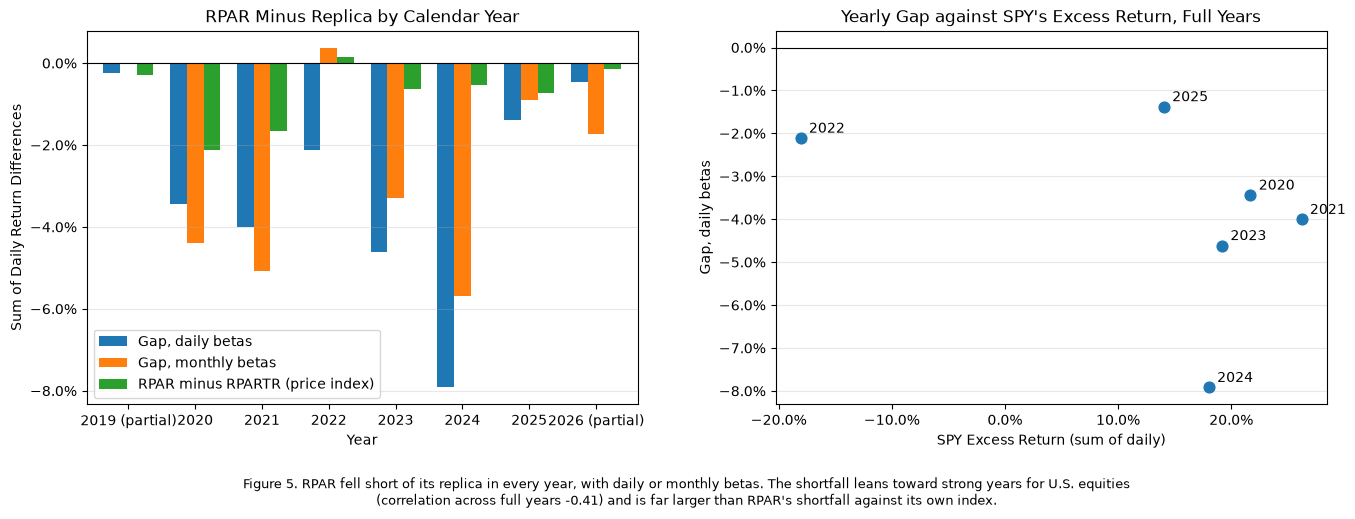

In [135]:
full_years = gap_by_year.drop(["2019 (partial)", "2026 (partial)", "Total"])

fig, axes = plt.subplots(1, 2, figsize = (16, 5.5))

gap_by_year.drop("Total")[["Gap", "Gap, monthly betas", "RPAR minus RPARTR"]].plot(kind = "bar", ax = axes[0], width = 0.75, rot = 0)
axes[0].set(title = "RPAR Minus Replica by Calendar Year", xlabel = "Year", ylabel = "Sum of Daily Return Differences")
axes[0].legend(["Gap, daily betas", "Gap, monthly betas", "RPAR minus RPARTR (price index)"])

axes[1].scatter(full_years["SPY"], full_years["Gap"], s = 60, zorder = 3)
for year, row in full_years.iterrows():
    axes[1].annotate(year, (row["SPY"], row["Gap"]), xytext = (6, 4), textcoords = "offset points")
axes[1].set(title = "Yearly Gap against SPY's Excess Return, Full Years", xlabel = "SPY Excess Return (sum of daily)", ylabel = "Gap, daily betas")
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))

for ax in axes:
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

fig.text(0.5, 0.01, "Figure 5. RPAR fell short of its replica in every year, with daily or monthly betas. The shortfall leans toward strong years for U.S. equities\n"
         f"(correlation across full years {full_years['Gap'].corr(full_years['SPY']):.2f}) and is far larger than RPAR's shortfall against its own index.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.2, wspace = 0.25)
plt.show()

> **The gap by year**
>
> `RPAR` fell short of the replica in every calendar year, from −1.4% (2025) to −7.9% (2024), for a total of −24.2% over its life ($t$ = −2.00), or about −3.5% a year. The sign is persistent, but no single year is significant except 2024 ($t$ = −2.34). The replica is fitted in sample without an intercept, so this total is the intercept 2.2 found (−3.55% a year), spread across the years.
>
> **Explanation 1: the funds hold different assets from the factor ETFs (basis).**
>
> `RPAR`'s sleeves are not `SPY`, `GLD` and `DBC`. Its equity sleeve is global (U.S., developed ex-U.S. and emerging markets), its commodity sleeve includes commodity-producer equities and gold, and its Treasuries are futures. The regression projects these onto the menu, so the replica earns the menu's returns. U.S. large caps outran global equities over most of this period, which would make a replica that holds `SPY` earn more than `RPAR`'s equity sleeve, with the gap widest when U.S. equities lead. The data lean that way but only weakly: across the six full years the gap correlates −0.41 with `SPY`'s excess return, and 2022, when `SPY` fell 18%, had the second-smallest gap (−2.1%, after 2025's −1.4%).
>
> **Explanation 2: implementation costs.**
>
> These include the 0.52% expense ratio, trading costs from rebalancing and rolling futures, and financing on Treasury-futures leverage above the `SHV` rate. Costs predict a fairly steady drag every year, unrelated to how markets moved. They would show up as `RPAR` lagging its own index, not only the replica.
>
> **What this file already rules out: the gap is not a daily-timing artifact.** Daily betas are attenuated by asynchronous closes (1.2, 2.2). Re-running the replica with full-sample monthly betas leaves the gap negative in 7 of 8 years (total −20.7% against −24.2%); only 2022 flips, to +0.4%.
>
> **What would separate explanations 1 and 2**
>
> * **The fund against its own index (in this file, with a caveat).** `RPAR`'s return minus `RPARTR`'s splits the gap into implementation (fund against index) and design or basis (index against replica). `RPAR` lagged `RPARTR` by −5.9% in total, about −0.9% a year, negative in 7 of 8 years, against the −3.5% a year it lagged the replica. That points to basis for most of the gap. But `RPARTR` is a price index without reinvested income, so the fund's true shortfall to its index is larger by the index's income. The total-return version of the index, from the issuer, settles how much is implementation.
> * **Sleeve holdings and their benchmarks (from the issuer).** Holdings by sleeve, plus returns on the matching global equity, emerging-market and commodity-equity indexes, would show directly whether the yearly gap tracks the return of `RPAR`'s equity and commodity sleeves minus `SPY` and `DBC`. If it is basis, the gap should regress on those return differences with slopes near the sleeve weights and leave little behind. If it is cost, the residual stays a steady negative of about the size of the fund-against-index shortfall.

***


# 4. Before It Existed

Cash is `SHV` throughout. Choose and state the estimation window and covariance estimator.


## 4.1

Build three portfolios of `SPY`, `TLT`, `TIP`, `GLD` and `DBC`: inverse variance, inverse volatility, and equal risk contribution. Re-estimate the weights at each month-end from trailing data and hold them through the next month. The backtest begins on 2008-02-01.

* State the estimation window and the covariance estimator.
* For the ERC portfolio, verify at one date that the five risk contributions are equal, and plot its weights through time.

#### Risk Contributions

For weights $\boldsymbol{w}$ on $n$ assets with covariance $\Sigma$, asset $i$'s risk contribution is $\text{RC}_i = w_i\,(\Sigma\boldsymbol{w})_i$, and the contributions sum to the portfolio variance $\boldsymbol{w}'\Sigma\boldsymbol{w}$. Inverse variance sets $w_i \propto 1/\sigma_i^2$, the rule the Harvard case calls risk parity. Inverse volatility sets $w_i \propto 1/\sigma_i$. Equal risk contribution (ERC) sets every $\text{RC}_i$ equal and is solved numerically. When every pair of assets has the same correlation, ERC coincides with inverse volatility; otherwise the three rules differ.


In [136]:
RP_ASSETS = ["SPY", "TLT", "TIP", "GLD", "DBC"]
RP_WINDOW = 252

rules = {"Inverse Variance": project_utils.inverse_variance_weights,
         "Inverse Volatility": project_utils.inverse_vol_weights,
         "ERC": project_utils.erc_weights}

#weights set at each month-end close from the trailing 252-day sample covariance, held through the next month
rp_weights = {name: project_utils.month_end_weights(returns[RP_ASSETS], rule, window = RP_WINDOW, start = "2008-01-31")
              for name, rule in rules.items()}

rp_returns, rp_held = {}, {}
for name, weights in rp_weights.items():
    rp_returns[name], rp_held[name] = project_utils.buy_and_hold_backtest(returns[RP_ASSETS], weights)

rp_returns = pd.DataFrame(rp_returns)

print(f"Rebalances: {len(rp_weights['ERC'])}, first set at {rp_weights['ERC'].index[0].date()}, last at {rp_weights['ERC'].index[-1].date()}")
print(f"Backtest returns: {rp_returns.index[0].date()} to {rp_returns.index[-1].date()}")

Rebalances: 225, first set at 2008-01-31, last at 2026-09-30
Backtest returns: 2008-02-01 to 2026-10-23


In [137]:
#verify the ERC solution at one rebalance date with the same covariance it was solved from
check_date = pd.Timestamp("2020-02-28")
check_cov = returns[RP_ASSETS].dropna().loc[:check_date].iloc[-RP_WINDOW:].cov() * 252

erc_check = project_utils.risk_contributions(rp_weights["ERC"].loc[check_date], check_cov)

display(erc_check.style.format({"Weight": "{:.2%}",
                                "Volatility": "{:.2%}",
                                "Risk Contribution": "{:.6f}",
                                "Share of Variance": "{:.2%}"})
                 .set_caption(f"ERC risk contributions at {check_date.date()}, annualized trailing {RP_WINDOW}-day covariance"))

print(f"Portfolio variance {erc_check['Risk Contribution'].sum():.6f} (volatility {np.sqrt(erc_check['Risk Contribution'].sum()):.2%}); "
      f"largest minus smallest contribution {erc_check['Risk Contribution'].max() - erc_check['Risk Contribution'].min():.1e}")

#the three rules differ because the correlations are not all equal
rule_comparison = pd.DataFrame({name: weights.loc[check_date] for name, weights in rp_weights.items()})

display(rule_comparison.style.format("{:.2%}")
                       .set_caption(f"Weights set by each rule at {check_date.date()}"))

,Weight,Volatility,Risk Contribution,Share of Variance
SPY,20.13%,13.58%,0.000475,20.00%
TLT,16.70%,12.63%,0.000475,20.00%
TIP,36.15%,3.97%,0.000475,20.00%
GLD,13.18%,12.48%,0.000475,20.00%
DBC,13.84%,14.04%,0.000475,20.00%


Portfolio variance 0.002373 (volatility 4.87%); largest minus smallest contribution 1.3e-10


,Inverse Variance,Inverse Volatility,ERC
SPY,6.26%,13.24%,20.13%
TLT,7.23%,14.24%,16.70%
TIP,73.23%,45.30%,36.15%
GLD,7.41%,14.41%,13.18%
DBC,5.86%,12.81%,13.84%


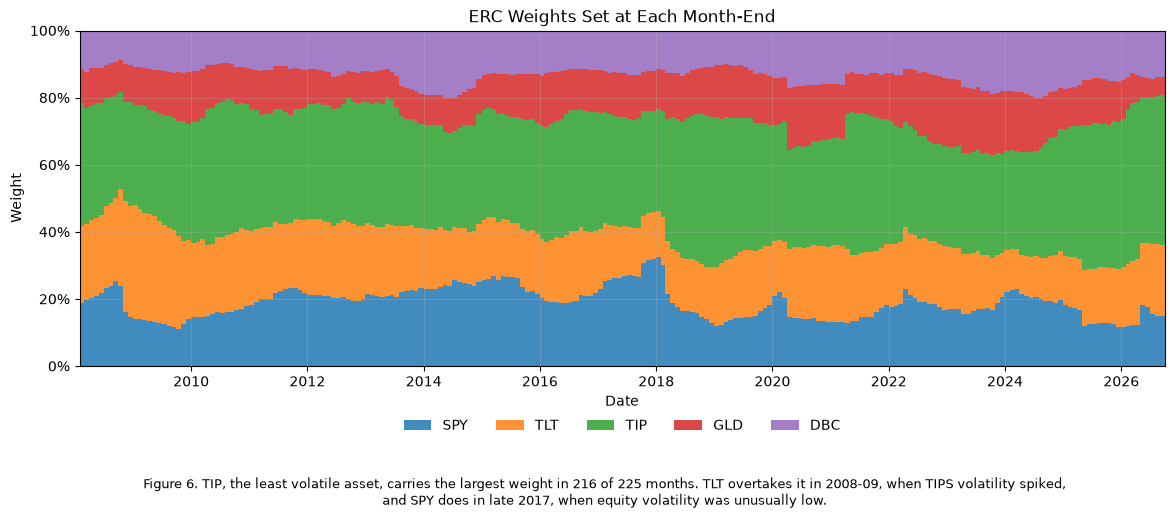

In [138]:
fig, ax = plt.subplots(figsize = (14, 5.5))

erc_plot = rp_weights["ERC"]
ax.stackplot(erc_plot.index, erc_plot.T.to_numpy(), labels = RP_ASSETS, step = "post", alpha = 0.85)

ax.set(title = "ERC Weights Set at Each Month-End", xlabel = "Date", ylabel = "Weight", ylim = (0, 1), xlim = (erc_plot.index[0], erc_plot.index[-1]))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc = "upper center", ncol = len(RP_ASSETS), bbox_to_anchor = (0.5, -0.12), frameon = False)
ax.grid(alpha = 0.3)

fig.text(0.5, 0.01, "Figure 6. TIP, the least volatile asset, carries the largest weight in 216 of 225 months. TLT overtakes it in 2008-09, when TIPS volatility spiked,\n"
         "and SPY does in late 2017, when equity volatility was unusually low.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.27)
plt.show()

> **Estimation window and covariance estimator**
>
> * **Window:** the trailing 252 trading days (one year) of daily returns, ending at the month-end close at which the weights are set. A year is long enough to estimate a 5-by-5 covariance matrix from 252 observations, and short enough for the weights to respond to changes in volatility.
> * **Estimator:** the equally weighted sample covariance matrix, annualized by 252. It is estimated on total returns rather than excess returns over `SHV`. `SHV`'s daily variance is negligible, so the two matrices are practically identical, and total returns let the window start before `SHV`'s January 2007 launch: the first full window ends 2007-02-28, the earliest start used in 4.2.
> * **Holding convention:** weights are set at the close of each month-end from data through that close and act from the first trading day of the next month. The positions are then held without trading, so the weights drift with returns until the next month-end. The first weights are set on 2008-01-31, so the backtest begins on 2008-02-01, with 225 rebalances through 2026-09-30.
>
> **ERC verification**
>
> At 2020-02-28, each asset's contribution $w_i(\Sigma\boldsymbol{w})_i$ is 0.000475, 20% of the portfolio variance of 0.002373 (4.87% volatility). The largest and smallest contributions differ by about $10^{-10}$. The three rules set different weights that day, for example 73% in `TIP` under inverse variance, 45% under inverse volatility and 36% under ERC, because the correlations are not all equal. Relative to inverse volatility, ERC cuts `TIP` (45% to 36%), whose risk largely overlaps with `TLT`'s, and raises `SPY` (13% to 20%), whose low or negative correlation with the bond ETFs makes its marginal risk smaller.
>
> **ERC weights through time (Figure 6)**
>
> `TIP` has the largest weight in 216 of 225 months, between 29% and 47%. `SPY` ranges from 11% to 33%, `TLT` from 12% to 34%, `GLD` from 5% to 21% and `DBC` from 9% to 20%. The weights move with relative volatility: `TLT` overtakes `TIP` in the 2008–09 crisis, when TIPS volatility spiked, and `SPY` takes the top weight in late 2017, when equity volatility was unusually low.

## 4.2

For the three unlevered rules, 60/40, the static four-way, `SPY` and `TLT`, report annualized mean and volatility, Sharpe ratio and maximum drawdown over the full backtest and the sub-periods before and after 2019-12-13. Also report calendar-year total returns, including 2008, 2013, 2020 and 2022.

Repeat the full-backtest statistics for the ERC rule and 60/40 with the backtest started in 2007, the earliest start the ETFs and your estimation window allow. What moves?


In [139]:
BACKTEST_SERIES = ["Inverse Variance", "Inverse Volatility", "ERC", "60/40", "static four-way", "SPY", "TLT"]
backtest_returns = pd.concat([rp_returns, returns.loc[rp_returns.index, ["60/40", "static four-way", "SPY", "TLT"]]], axis = 1)[BACKTEST_SERIES]

backtest_periods = {f"Full backtest, {backtest_returns.index[0].date()} to {backtest_returns.index[-1].date()}": backtest_returns,
                    "Before RPAR, to 2019-12-12": backtest_returns.loc[:"2019-12-12"],
                    "After RPAR, from 2019-12-13": backtest_returns.loc["2019-12-13":]}

stat_cols = ["Annualized Mean", "Annualized Volatility", "Sharpe Ratio", "Max Drawdown", "Peak Date", "Trough Date", "Recovery Date"]

backtest_stats = pd.concat({period: project_utils.performance_stats(df, returns.loc[df.index, "SHV"])[stat_cols]
                            for period, df in backtest_periods.items()}, names = ["Period", "Strategy"])

backtest_format = {"Annualized Mean": "{:.2%}",
                   "Annualized Volatility": "{:.2%}",
                   "Sharpe Ratio": "{:.2f}",
                   "Max Drawdown": "{:.2%}",
                   "Peak Date": format_date,
                   "Trough Date": format_date,
                   "Recovery Date": format_date}

display(backtest_stats.style.format(backtest_format)
                      .set_caption("Unlevered rules and benchmarks; Sharpe ratios on excess returns over SHV"))

In [140]:
backtest_calendar = project_utils.calendar_year_returns(backtest_returns).T
backtest_calendar = backtest_calendar.rename(columns = {2008: "2008 (Feb-Dec)", 2026: "2026 YTD"})

highlight_years = ["2008 (Feb-Dec)", 2013, 2020, 2022]

display(backtest_calendar.style.format("{:.2%}")
                         .set_properties(subset = highlight_years, **{"font-weight": "bold"})
                         .set_caption("Calendar-year total returns over the backtest; 2008 starts 2008-02-01 and 2026 ends 2026-10-23"))

,2008 (Feb-Dec),2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026 YTD
Inverse Variance,0.30%,4.03%,8.85%,12.64%,6.98%,-6.28%,1.35%,-4.26%,6.39%,6.67%,-1.31%,10.89%,13.00%,6.91%,-11.85%,6.50%,6.80%,9.26%,2.49%
Inverse Volatility,-3.70%,6.17%,12.02%,12.25%,7.29%,-5.91%,1.23%,-6.15%,7.92%,8.78%,-2.24%,13.86%,13.22%,9.44%,-11.16%,7.34%,8.34%,13.44%,6.54%
ERC,-3.21%,3.64%,12.12%,12.95%,7.66%,-3.63%,2.73%,-5.60%,8.29%,10.46%,-1.82%,15.11%,11.59%,9.44%,-11.70%,7.39%,8.72%,13.47%,8.02%
60/40,-14.77%,13.26%,13.46%,8.29%,11.26%,15.61%,11.95%,1.78%,7.80%,13.76%,-1.95%,21.77%,16.94%,15.09%,-16.38%,16.98%,14.24%,14.32%,6.32%
static four-way,-10.63%,11.30%,17.27%,11.75%,7.83%,-6.02%,0.94%,-9.62%,10.69%,12.34%,-4.46%,19.22%,15.07%,14.49%,-8.29%,8.99%,11.08%,22.51%,12.54%
SPY,-32.74%,26.37%,15.06%,1.89%,15.99%,32.31%,13.46%,1.25%,12.00%,21.70%,-4.56%,31.22%,18.37%,28.75%,-18.17%,26.19%,24.89%,17.72%,12.32%
TLT,31.18%,-21.80%,9.05%,33.96%,2.63%,-13.37%,27.30%,-1.79%,1.18%,9.18%,-1.61%,14.12%,18.15%,-4.60%,-31.24%,2.77%,-8.06%,4.25%,-3.42%


In [141]:
#earliest start the ETFs and the 252-day window allow: first full window ends at the 2007-02-28 close
early_erc_weights = project_utils.month_end_weights(returns[RP_ASSETS], project_utils.erc_weights, window = RP_WINDOW)
early_erc_returns, _ = project_utils.buy_and_hold_backtest(returns[RP_ASSETS], early_erc_weights)

early_returns = pd.DataFrame({"ERC": early_erc_returns,
                              "60/40": returns.loc[early_erc_returns.index, "60/40"]})

start_comparison = pd.concat({f"From {early_returns.index[0].date()}": project_utils.performance_stats(early_returns, returns.loc[early_returns.index, "SHV"])[stat_cols],
                              f"From {backtest_returns.index[0].date()}": backtest_stats.xs(list(backtest_periods)[0]).loc[["ERC", "60/40"]]},
                             names = ["Start", "Strategy"]).swaplevel()
start_comparison = start_comparison.reindex(["ERC", "60/40"], level = "Strategy")

display(start_comparison.style.format(backtest_format)
                        .set_caption("Full-backtest statistics for ERC and 60/40 by start date"))

print("Return from 2007-03-01 to 2008-01-31: " + ", ".join(f"{name} {ret:.2%}" for name, ret in ((1 + early_returns.loc[:"2008-01-31"]).prod() - 1).items()))

Return from 2007-03-01 to 2008-01-31: ERC 14.09%, 60/40 4.79%


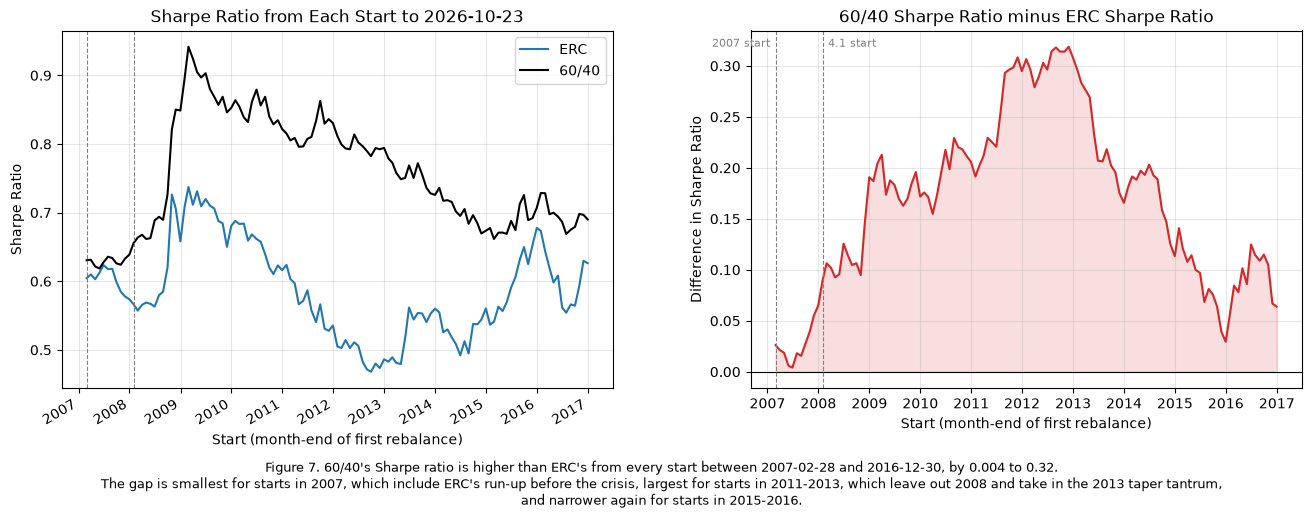

In [142]:
#rerun ERC and 60/40 from every month-end rebalance through 2016, so every sample still runs at least ten years
start_dates = early_erc_weights.loc[:"2016-12-31"].index

start_sharpes = {}
for start in start_dates:
    sample = early_returns.loc[early_returns.index > start]
    sample_excess = sample.sub(returns.loc[sample.index, "SHV"], axis = 0)
    start_sharpes[start] = sample_excess.mean() / sample_excess.std() * np.sqrt(252)

start_sharpes = pd.DataFrame(start_sharpes).T
start_sharpes["60/40 minus ERC"] = start_sharpes["60/40"] - start_sharpes["ERC"]

fig, axes = plt.subplots(1, 2, figsize = (16, 5.5))

start_sharpes[["ERC", "60/40"]].plot(ax = axes[0], linewidth = 1.5, color = ["tab:blue", "black"])
axes[0].set(title = f"Sharpe Ratio from Each Start to {early_returns.index[-1].date()}", xlabel = "Start (month-end of first rebalance)", ylabel = "Sharpe Ratio")

axes[1].plot(start_sharpes.index, start_sharpes["60/40 minus ERC"], linewidth = 1.5, color = "tab:red")
axes[1].fill_between(start_sharpes.index, start_sharpes["60/40 minus ERC"], 0, color = "tab:red", alpha = 0.15)
axes[1].axhline(0, color = "black", linewidth = 0.8)
axes[1].set(title = "60/40 Sharpe Ratio minus ERC Sharpe Ratio", xlabel = "Start (month-end of first rebalance)", ylabel = "Difference in Sharpe Ratio")

#the two starts compared in the table above
for ax in axes:
    for date in [early_erc_weights.index[0], rp_weights["ERC"].index[0]]:
        ax.axvline(date, color = "gray", linestyle = "--", linewidth = 0.8)
    ax.grid(alpha = 0.3)

for date, label, side in [(early_erc_weights.index[0], "2007 start", "right"), (rp_weights["ERC"].index[0], "4.1 start", "left")]:
    axes[1].annotate(label, (date, start_sharpes["60/40 minus ERC"].max()), xytext = (-4 if side == "right" else 4, 0), textcoords = "offset points",
                     ha = side, fontsize = 8, color = "gray")

fig.text(0.5, 0.01, f"Figure 7. 60/40's Sharpe ratio is higher than ERC's from every start between {start_dates[0].date()} and {start_dates[-1].date()}, by {start_sharpes['60/40 minus ERC'].min():.3f} to {start_sharpes['60/40 minus ERC'].max():.2f}.\n"
         "The gap is smallest for starts in 2007, which include ERC's run-up before the crisis, largest for starts in 2011-2013, which leave out 2008 and take in the 2013 taper tantrum,\n"
         "and narrower again for starts in 2015-2016.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.23, wspace = 0.25)
plt.show()

> **Full backtest**
>
> Unlevered, the three risk-parity rules run at between a half and two-thirds of 60/40's volatility (6.3% to 7.3% against 11.3%) and hold their maximum drawdowns to −16.6% to −18.0%, against −30.8% for 60/40. They also earn much less (4.2% to 5.5% a year against 8.9%), and none beats 60/40's Sharpe ratio of 0.66. ERC comes closest at 0.57, then inverse volatility (0.53) and inverse variance (0.44). The ordering follows how heavily each rule leans on the lowest-volatility asset, `TIP`: inverse variance puts the most there and earns the least for its risk. Matching 60/40's return takes leverage (4.3).
>
> **Before and after RPAR's launch**
>
> * **Before 2019-12-13**, ERC's Sharpe ratio was 0.62 against 60/40's 0.71, and its worst drawdown (−17.8%) came in 2008, when 60/40 fell 30.8%.
> * **After**, every rule's Sharpe ratio fell (ERC to 0.50, inverse variance to 0.30) while the static four-way reached 0.77, the best of the seven. ERC's 2022 drawdown (−18.0%) was as deep as its 2008 one. For risk parity, 2022 was as bad as the financial crisis; for 60/40 it was milder (−21.0%).
>
> **Calendar years**
>
> * **2008 (from February):** the rules lost 3.7% at most, and inverse variance gained 0.3%, while 60/40 lost 14.8% and `SPY` 32.7%. `TLT` (up 31.2%) carried them, not TIPS: for ERC, `TLT` added 9.1%, more than offsetting `SPY`'s −8.1%, while `TIP` (−1.1%) and `DBC` (−2.6%) lost money (Figure 8). This is risk parity's best year relative to 60/40.
> * **2013 (taper tantrum):** the rules lost 3.6% to 6.3% while 60/40 gained 15.6%. Bonds, TIPS and gold fell together while equities rallied, so the heavy weights in the falling assets cost them. For ERC, `SPY` added 6.2% while `TLT`, `TIP` and `GLD` each cost about 3% (Figure 8). This is their worst year relative to 60/40.
> * **2020:** all gained. ERC returned 11.6% against 60/40's 16.9%: the bond weights paid off in March, but the equity weight was too small to keep up with the rebound. Gold was ERC's largest contributor (4.1%); `SPY` added only 1.3%, against 13.5% inside 60/40 (Figure 8).
> * **2022:** stocks and bonds fell together. ERC lost 11.7%, less than 60/40 (−16.4%) but more than the static four-way (−8.3%), whose 50% in gold and commodities offset more of the bond losses than ERC's 27% to 34% through 2022. `TLT` and `TIP` cost ERC 10.7% between them, and `DBC` (+2.5%) was the only real offset (Figure 8).
>
> **Starting in 2007: what moves**
>
> Starting at the earliest date the ETFs and the 252-day window allow, 2007-03-01, adds 11 months in which ERC gained 14.1% and 60/40 4.8%, as commodities, gold and TIPS rallied into the crisis. ERC's mean rises from 5.51% to 5.93% and its Sharpe ratio from 0.57 to 0.60. 60/40's Sharpe ratio falls from 0.66 to 0.63, and its drawdown deepens from −30.8% to −31.4%, because its peak moves back to 2007-12-10 and its recovery to 2010-09-20. The Sharpe gap between 60/40 and ERC shrinks from 0.09 to 0.03, while volatilities move by less than 0.1 percentage point and ERC's drawdown does not change. Risk parity's lower volatility and shallower drawdowns hold whatever the start date. Its Sharpe ratio relative to 60/40 does not: the gap depends on a start date that moves by only eleven months.
>
> Figure 7 repeats the comparison for every month-end start from 2007-02-28 to 2016-12-30, so every sample runs at least ten years. 60/40's Sharpe ratio is higher from every start, so the ranking never flips; only the size of the gap moves. It is smallest (0.004) for a start in mid-2007, near 0.1 for the 2008 start used here, largest (0.32) for starts in late 2012, which leave out 2008 and take in 2013, and back to 0.03 to 0.14 for starts in 2015-2016. Over this sample no start date makes ERC the better risk-adjusted strategy; the start date decides only whether it trails 60/40 slightly or by a lot.

## 4.3

Lever the ERC portfolio, borrowing at `SHV`, to match 60/40's volatility over the full backtest. Report

* the leverage applied
* annualized mean and volatility, Sharpe ratio and maximum drawdown
* one-way turnover per year, counting changes in both weights and leverage


In [143]:
from scipy.optimize import brentq

backtest_rf = returns.loc[backtest_returns.index, "SHV"]
target_vol = backtest_returns["60/40"].std() * np.sqrt(252)

def levered_erc_vol(leverage):
    levered, _, _ = project_utils.levered_backtest(returns[RP_ASSETS], rp_weights["ERC"], returns["SHV"], leverage = leverage)
    return levered.std() * np.sqrt(252)

#one constant leverage, chosen so the levered ERC's full-backtest volatility equals 60/40's
ERC_LEVERAGE = brentq(lambda leverage: levered_erc_vol(leverage) - target_vol, 1, 4)

levered_erc_returns, levered_erc_positions, levered_erc_turnover = project_utils.levered_backtest(returns[RP_ASSETS], rp_weights["ERC"], returns["SHV"], leverage = ERC_LEVERAGE)
_, erc_positions, erc_turnover = project_utils.levered_backtest(returns[RP_ASSETS], rp_weights["ERC"], returns["SHV"], leverage = 1)

backtest_years = len(backtest_returns) / 252

levered_comparison = pd.DataFrame({"Levered ERC": levered_erc_returns,
                                   "ERC": backtest_returns["ERC"],
                                   "60/40": backtest_returns["60/40"]})

levered_stats = project_utils.performance_stats(levered_comparison, backtest_rf)[stat_cols]
levered_stats.insert(0, "Leverage", [ERC_LEVERAGE, 1.0, 1.0])
levered_stats["One-Way Turnover per Year"] = [levered_erc_turnover.sum() / backtest_years, erc_turnover.sum() / backtest_years, np.nan]

print(f"Leverage: {ERC_LEVERAGE:.3f}x, set to match 60/40's full-backtest volatility of {target_vol:.2%}")

display(levered_stats.style.format({**backtest_format, "Leverage": "{:.2f}x", "One-Way Turnover per Year": "{:.2f}"}, na_rep = "—")
                     .set_caption(f"Levered ERC against unlevered ERC and 60/40, {backtest_returns.index[0].date()} to {backtest_returns.index[-1].date()}"))

#leverage just before each reset, after a month of drift
month_end_gross = {date: (levered_erc_positions.loc[date] * (1 + returns.loc[date, RP_ASSETS])).sum() / (1 + levered_erc_returns.loc[date])
                   for date in levered_erc_turnover.index}
month_end_gross = pd.Series(month_end_gross)

#the risky positions drift in proportion with or without leverage, so the weight changes alone cost leverage x the unlevered turnover
weight_turnover = ERC_LEVERAGE * erc_turnover.sum() / backtest_years

print(f"Turnover per year: {levered_erc_turnover.sum() / backtest_years:.2f}, of which weight changes {weight_turnover:.2f} "
      f"and restoring the drifted leverage {levered_erc_turnover.sum() / backtest_years - weight_turnover:.2f}")
print(f"Leverage just before each reset: mean {month_end_gross.mean():.2f}x, range {month_end_gross.min():.2f}x to {month_end_gross.max():.2f}x")

Leverage: 1.555x, set to match 60/40's full-backtest volatility of 11.34%


,Leverage,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown,Peak Date,Trough Date,Recovery Date,One-Way Turnover per Year
Levered ERC,1.55x,7.77%,11.34%,0.56,-27.41%,2008-05-21,2008-10-27,2010-08-02,0.35
ERC,1.00x,5.51%,7.26%,0.57,-17.97%,2022-03-08,2022-10-20,2024-07-16,0.22
60/40,1.00x,8.86%,11.34%,0.66,-30.80%,2008-05-19,2009-03-09,2010-04-23,—


Turnover per year: 0.35, of which weight changes 0.34 and restoring the drifted leverage 0.01
Leverage just before each reset: mean 1.55x, range 1.50x to 1.67x


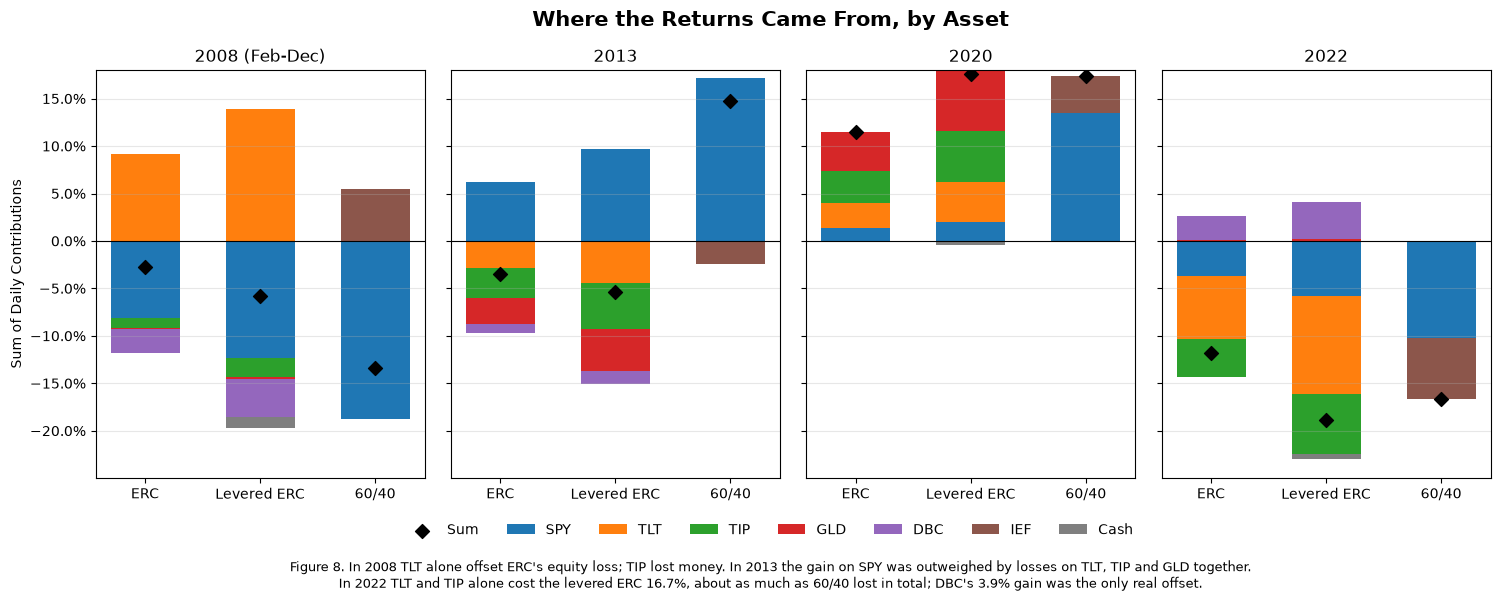

In [144]:
CONTRIBUTION_YEARS = [2008, 2013, 2020, 2022]
CONTRIBUTION_COLS = RP_ASSETS + ["IEF", "Cash"]

#each day's return split by asset: the weight (or position) held at the start of the day times the asset's return;
#Cash is the levered ERC's borrowing cost at SHV, and 60/40 holds 0.6 SPY and 0.4 IEF every day
asset_returns = returns.loc[backtest_returns.index]

contributions = {"ERC": rp_held["ERC"].loc[backtest_returns.index] * asset_returns[RP_ASSETS],
                 "Levered ERC": (levered_erc_positions * asset_returns[RP_ASSETS]).assign(Cash = (1 - levered_erc_positions.sum(axis = 1)) * asset_returns["SHV"]),
                 "60/40": pd.DataFrame({"SPY": 0.6 * asset_returns["SPY"], "IEF": 0.4 * asset_returns["IEF"]})}

#sums of daily contributions by calendar year; they add up to the sum of daily portfolio returns, close to but not equal to the compounded return
contributions_by_year = pd.concat({year: pd.DataFrame({name: df.loc[str(year)].sum() for name, df in contributions.items()}).T
                                   for year in CONTRIBUTION_YEARS}, names = ["Year", "Strategy"])[CONTRIBUTION_COLS]
contributions_by_year["Sum"] = contributions_by_year.sum(axis = 1)
contributions_by_year["Compounded Return"] = [(1 + levered_comparison.loc[str(year), name]).prod() - 1 for year, name in contributions_by_year.index]

display(contributions_by_year.style.format("{:.2%}", na_rep = "—")
                             .set_caption("Sums of daily return contributions by asset in four calendar years (2008 from February)"))

fig, axes = plt.subplots(1, len(CONTRIBUTION_YEARS), figsize = (18, 6), sharey = True)
colors = dict(zip(CONTRIBUTION_COLS, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:gray"]))

for ax, year in zip(axes, CONTRIBUTION_YEARS):
    year_data = contributions_by_year.loc[year].fillna(0)

    #stack gains upward and losses downward from zero
    positive = np.zeros(len(year_data))
    negative = np.zeros(len(year_data))
    for asset in CONTRIBUTION_COLS:
        values = year_data[asset].to_numpy()
        ax.bar(year_data.index, values, bottom = np.where(values >= 0, positive, negative), width = 0.6, color = colors[asset], label = asset)
        positive += np.clip(values, 0, None)
        negative += np.clip(values, None, 0)

    ax.scatter(year_data.index, year_data["Sum"], marker = "D", s = 50, color = "black", zorder = 3, label = "Sum")

    ax.set(title = "2008 (Feb-Dec)" if year == 2008 else str(year), xlabel = "")
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

axes[0].set_ylabel("Sum of Daily Contributions")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.08), frameon = False)

fig.suptitle("Where the Returns Came From, by Asset", fontsize = 15, fontweight = "bold")

levered_2022 = contributions_by_year.loc[(2022, "Levered ERC")]
fig.text(0.5, 0.01, "Figure 8. In 2008 TLT alone offset ERC's equity loss; TIP lost money. In 2013 the gain on SPY was outweighed by losses on TLT, TIP and GLD together.\n"
         f"In 2022 TLT and TIP alone cost the levered ERC {-levered_2022[['TLT', 'TIP']].sum():.1%}, about as much as 60/40 lost in total; DBC's {levered_2022['DBC']:.1%} gain was the only real offset.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.2, wspace = 0.08)
plt.show()

> **Construction**
>
> At each month-end the portfolio is reset to $L$ times the ERC weights from 4.1, as fractions of net asset value, with $L - 1$ borrowed at `SHV`'s return. Between resets nothing is traded, as in 4.1, so the weights and the leverage both drift; each reset restores both. $L$ is one constant, solved so that the levered portfolio's volatility over the full backtest (2008-02-01 to 2026-10-23) equals 60/40's 11.34%. That uses the whole sample, so it is a hindsight choice: an allocator in 2008 could not have known it.
>
> **Results**
>
> * **Leverage: 1.55x.** Just before each reset, after a month of drift, leverage ranged from 1.50x to 1.67x.
> * **Mean, volatility and Sharpe ratio.** The levered ERC earns 7.77% a year at 11.34% volatility, against 60/40's 8.86% at the same volatility. Its Sharpe ratio (0.56) equals the unlevered ERC's, as it should when the borrowing rate is the cash rate, and it stays below 60/40's 0.66. Matched for risk, ERC gives up about 1.1% a year to 60/40 over this backtest.
> * **Maximum drawdown: −27.4%** (2008-05-21 to 2008-10-27, recovered 2010-08-02), against 60/40's −30.8%. Leverage brings the 2008 drawdown back: unlevered, ERC's worst loss was −18.0% in 2022.
> * **Turnover: 0.35 a year one-way**, about 3% of NAV a month. Nearly all of it is the monthly change in weights (0.34, which is 1.55 times the unlevered ERC's 0.22); restoring the drifted leverage adds about 0.01.
>
> At equal volatility, the levered ERC no longer has the drawdown advantage it had unlevered in 4.2: its worst loss is only 3.4 percentage points shallower than 60/40's. In 2022 it lost 18.5% to 60/40's 16.4%, since leverage scaled up the losses in its bond and TIPS weights: `TLT` and `TIP` alone cost it 16.7%, about what 60/40 lost in total, and `DBC`'s 3.9% gain was the only real offset (Figure 8).

## 4.4

Over `RPAR`'s life, compare the ERC weights with `RPAR`'s revealed allocation, its betas from 2.2 scaled to sum to one, and regress `RPAR`'s daily excess return on the levered ERC portfolio's. Report

* the two allocations side by side
* the slope, the annualized intercept with its $t$-statistic, and $R^2$

Does the 2008 to 2019 record change what a reader of Section 1 would conclude? Keep the allocation rule and `RPAR`'s implementation of it separate in the answer.


In [145]:
rpar_dates = excess_returns["RPAR"].dropna().index

#RPAR's revealed allocation: its full-life betas from 2.2 scaled to sum to one
revealed = factor_regressions.loc[(slice(None), "RPAR"), FACTORS].astype(float).droplevel("Fund")
revealed = revealed.div(revealed.sum(axis = 1), axis = 0)

#ERC weights over the same dates: the month-end targets and the drifted weights actually held
#start from the last month-end target set before RPAR's first return, which was held through its first weeks
erc_target_rpar_life = rp_weights["ERC"].loc[rp_weights["ERC"].index[rp_weights["ERC"].index < rpar_dates[0]][-1]:]
erc_held_rpar_life = rp_held["ERC"].loc[rpar_dates]

#RPAR's stated index allocation, with its commodity sleeve split evenly between gold and broad commodities for comparison
stated = pd.Series({"SPY": 0.25, "TLT": 0.15, "TIP": 0.35, "GLD": 0.125, "DBC": 0.125})

allocations = pd.DataFrame({"ERC, mean month-end target": erc_target_rpar_life.mean(),
                            "ERC, mean held": erc_held_rpar_life.mean(),
                            "RPAR revealed, daily betas": revealed.loc["Daily"],
                            "RPAR revealed, monthly betas": revealed.loc["Monthly"],
                            "RPAR index, stated": stated})
allocations.loc["Sum of betas (unscaled)"] = [np.nan, np.nan,
                                              factor_regressions.loc[("Daily", "RPAR"), "Sum of Betas"],
                                              factor_regressions.loc[("Monthly", "RPAR"), "Sum of Betas"],
                                              np.nan]

display(allocations.style.format("{:.1%}", na_rep = "—")
                   .format("{:.2f}", na_rep = "—", subset = (["Sum of betas (unscaled)"], slice(None)))
                   .set_caption(f"ERC weights and RPAR's allocation over RPAR's life, {rpar_dates[0].date()} to {rpar_dates[-1].date()}"))

,"ERC, mean month-end target","ERC, mean held","RPAR revealed, daily betas","RPAR revealed, monthly betas","RPAR index, stated"
SPY,16.6%,16.6%,23.4%,20.4%,25.0%
TLT,17.7%,17.6%,21.9%,25.8%,15.0%
TIP,35.6%,35.4%,39.0%,35.8%,35.0%
GLD,14.8%,14.9%,12.1%,11.2%,12.5%
DBC,15.3%,15.4%,3.6%,6.8%,12.5%
Sum of betas (unscaled),—,—,1.39,1.53,—


In [146]:
levered_erc_excess = (levered_erc_returns - returns["SHV"]).rename("Levered ERC")

#daily regression as asked, and monthly sums of the same daily excess returns to remove the asynchronous-close attenuation (1.2, 2.2)
rpar_erc_daily = pd.concat([excess_returns.loc[rpar_dates, "RPAR"], levered_erc_excess.loc[rpar_dates]], axis = 1)
rpar_erc_monthly = rpar_erc_daily.groupby(rpar_erc_daily.index.to_period("M")).sum().iloc[1:-1]

rpar_on_erc = pd.DataFrame({"Daily": project_utils.regression_stats(rpar_erc_daily["RPAR"], rpar_erc_daily["Levered ERC"]),
                            "Monthly (full months)": project_utils.regression_stats(rpar_erc_monthly["RPAR"], rpar_erc_monthly["Levered ERC"], periods = 12)})
rpar_on_erc = rpar_on_erc.rename({"Levered ERC": "Slope", "Alpha": "Annualized Intercept"})

display(rpar_on_erc.style.format("{:.2f}")
                   .format("{:.2%}", subset = (["Annualized Intercept", "Tracking Error"], slice(None)))
                   .set_caption("RPAR's excess return on the levered ERC portfolio's, over RPAR's life"))

#the rule and RPAR side by side over RPAR's life and over the backtest before it
rule_vs_rpar = pd.concat({"RPAR's life": project_utils.performance_stats(pd.DataFrame({"RPAR": returns.loc[rpar_dates, "RPAR"],
                                                                                      "Levered ERC": levered_erc_returns.loc[rpar_dates],
                                                                                      "60/40": returns.loc[rpar_dates, "60/40"]}),
                                                                        returns.loc[rpar_dates, "SHV"])[stat_cols[:4]],
                          "2008-02-01 to 2019-12-12": project_utils.performance_stats(pd.DataFrame({"Levered ERC": levered_erc_returns.loc[:"2019-12-12"],
                                                                                                   "60/40": returns.loc[levered_erc_returns.loc[:"2019-12-12"].index, "60/40"]}),
                                                                                     returns.loc[levered_erc_returns.loc[:"2019-12-12"].index, "SHV"])[stat_cols[:4]]},
                         names = ["Period", "Strategy"])

display(rule_vs_rpar.style.format(backtest_format)
                    .set_caption("The levered ERC rule and RPAR, each at its own volatility"))

,Daily,Monthly (full months)
Slope,0.85,1.02
Annualized Intercept,-3.79%,-4.56%
Alpha t-stat,-1.65,-2.58
R-squared,0.77,0.89
Tracking Error,6.02%,4.52%


Date,2019 (partial),2020,2021,2022,2023,2024,2025,2026 (partial)
RPAR minus Levered ERC,-0.77%,1.30%,-6.72%,-5.68%,-2.07%,-10.04%,-0.80%,-7.58%


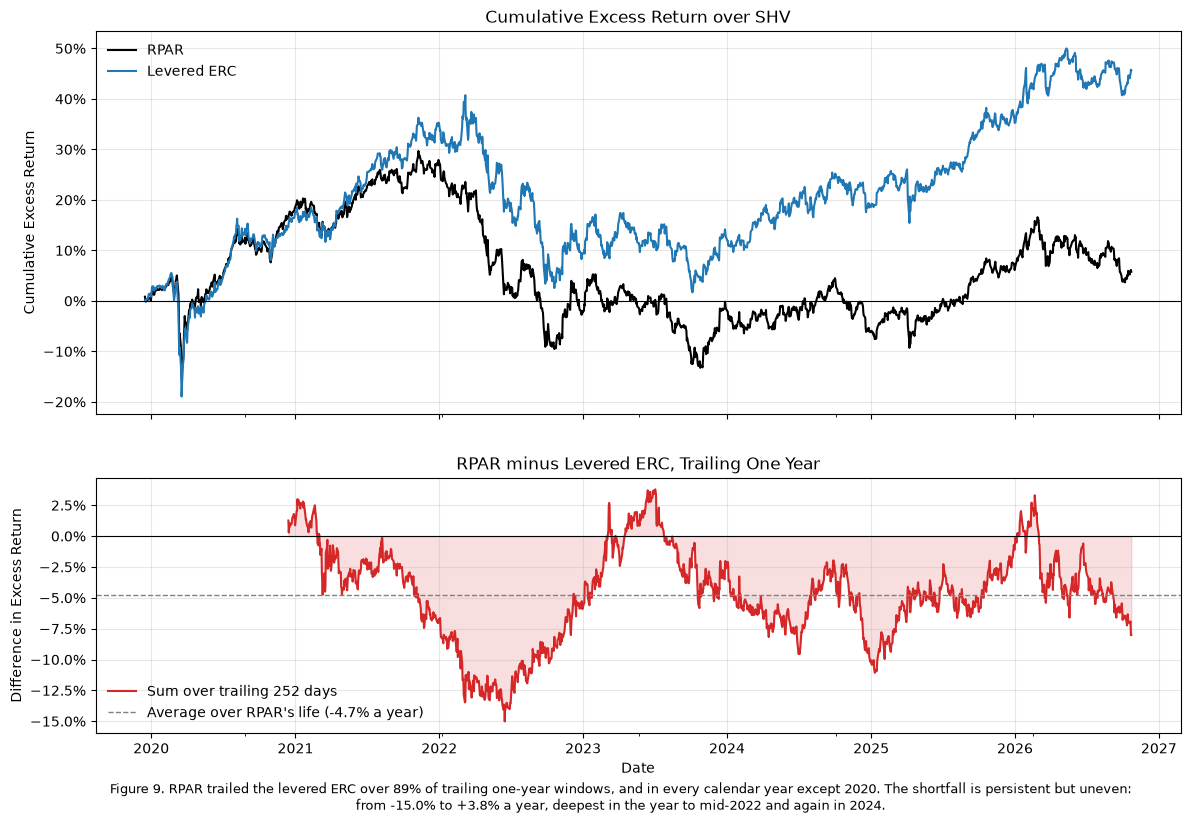

In [147]:
rpar_gap = (rpar_erc_daily["RPAR"] - rpar_erc_daily["Levered ERC"]).rename("RPAR minus Levered ERC")
trailing_gap = rpar_gap.rolling(252).sum()

#sum of daily excess-return differences by calendar year
rpar_gap_by_year = rpar_gap.groupby(rpar_gap.index.year).sum().to_frame().T
rpar_gap_by_year = rpar_gap_by_year.rename(columns = {2019: "2019 (partial)", rpar_gap.index[-1].year: f"{rpar_gap.index[-1].year} (partial)"})

display(rpar_gap_by_year.style.format("{:.2%}")
                        .set_caption("RPAR minus the levered ERC by calendar year, sum of daily excess returns"))

fig, axes = plt.subplots(2, 1, figsize = (14, 9), sharex = True, gridspec_kw = {"height_ratios": [3, 2]})

((1 + rpar_erc_daily).cumprod() - 1).plot(ax = axes[0], linewidth = 1.5, color = ["black", "tab:blue"])
axes[0].set(title = "Cumulative Excess Return over SHV", ylabel = "Cumulative Excess Return")
axes[0].legend(frameon = False)

axes[1].plot(trailing_gap.index, trailing_gap, linewidth = 1.5, color = "tab:red", label = "Sum over trailing 252 days")
axes[1].fill_between(trailing_gap.index, trailing_gap, 0, color = "tab:red", alpha = 0.15)
axes[1].axhline(rpar_gap.mean() * 252, color = "gray", linestyle = "--", linewidth = 1, label = f"Average over RPAR's life ({rpar_gap.mean() * 252:.1%} a year)")
axes[1].set(title = "RPAR minus Levered ERC, Trailing One Year", xlabel = "Date", ylabel = "Difference in Excess Return")
axes[1].legend(frameon = False, loc = "lower left")

for ax in axes:
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha = 0.3)

fig.text(0.5, 0.01, f"Figure 9. RPAR trailed the levered ERC over {(trailing_gap.dropna() < 0).mean():.0%} of trailing one-year windows, and in every calendar year except 2020. The shortfall is persistent but uneven:\n"
         f"from {trailing_gap.min():.1%} to {trailing_gap.max():+.1%} a year, deepest in the year to mid-2022 and again in 2024.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.1, hspace = 0.2)
plt.show()

> **The two allocations**
>
> ERC and `RPAR`'s revealed allocation agree on the main point: `TIP` is the largest position in both (35% to 39%). They differ at the edges. `RPAR` holds more `SPY` (20% to 23% against ERC's 17%) and more `TLT` (22% to 26% against 18%), and much less `DBC` (4% to 7% against 15%). That pattern fits its commodity sleeve holding commodity-producer equities and gold rather than broad commodity futures, so its commodity risk loads on `SPY` and `GLD` instead of `DBC` (3.3). Its unscaled sum of betas, 1.39 daily and 1.53 monthly, is close to the 1.55x leverage of the levered ERC.
>
> **`RPAR` on the levered ERC**
>
> Daily: slope 0.85, annualized intercept −3.79% ($t$ = −1.65), $R^2$ 0.77. On monthly sums of the same returns, which remove the daily attenuation seen in 1.2 and 2.2: slope 1.02, intercept −4.56% ($t$ = −2.58), $R^2$ 0.89. At the monthly horizon, `RPAR` moves one-for-one with the levered ERC rule but trails it by about 4.5% a year.
>
> **Is the shortfall steady?** Mostly, yes (Figure 9). `RPAR` tracked the rule closely through 2020, including the March crash, and trailed it in every calendar year since: by 6.7% in 2021, 5.7% in 2022, 2.1% in 2023, 10.0% in 2024 and 0.8% in 2025 (sums of daily excess returns). Over trailing one-year windows it was behind 89% of the time, by 4.7% a year on average. The size swings widely, though, from −15.0% in the year to mid-2022 to +3.8% in mid-2023. A shortfall present in almost every year points to something structural, not bad luck. Swings this large around it point to basis, the fund's holdings differing from the five ETFs (3.3). Costs alone would produce a smaller, smoother drag. Over `RPAR`'s life, at nearly the same volatility (12.6% against 12.9%), the rule earned 9.1% a year with a Sharpe ratio of 0.49, while `RPAR` earned 4.3% with 0.13.
>
> **Does the 2008–2019 record change the Section 1 conclusion?**
>
> * **The allocation rule: yes, partly.** Section 1 saw only `RPAR`'s seven years and a Sharpe ratio of 0.13. The rule's longer record is better. Levered to 60/40's risk, it had a Sharpe ratio of 0.61 from 2008 to 2019 and 0.49 over `RPAR`'s life, with a maximum drawdown of −27.4% in 2008 against 60/40's −30.8%. But it did not beat 60/40 in either period (0.71 and 0.57). The longer record says the rule works, but gives no evidence that it beats a plain stock-bond mix at equal risk. The 2022 loss is the rule's, not only `RPAR`'s: the levered ERC's drawdown over `RPAR`'s life was −26.9%, close to `RPAR`'s −30.1%.
> * **`RPAR`'s implementation: no.** The 2008–2019 backtest contains no `RPAR`, so it says nothing about how well the fund implements the rule. Over the years both exist, `RPAR` trails the rule by about 4.5% a year with $R^2$ near 0.9, and that gap, not the rule, accounts for most of the distance between `RPAR`'s 0.13 Sharpe ratio and the rule's 0.49. The basis and cost explanations of 3.3 apply here too. The Section 1 finding that `RPAR` lagged the static four-way is mostly a finding about the fund, and the longer history leaves it unchanged.

***


# 5. What Broke

| Episode | Window |
|---|---|
| 2020 | 2020-02-19 to 2020-03-23 |
| 2022 | 2022-01-03 to 2022-10-24 |
| Calm | 2023-01-03 to 2024-12-31 |

For the VaR backtests, extend the 2020 window to April 30 and the 2022 window to December 30. A breach is a day whose return falls below the forecast. With the 252-day burn-in, `RPAR` and `DBMF` have no historical-simulation forecast inside the 2020 window; their 2020 rows carry EWMA only. Attribution in 5.3 uses the shorter windows tabled above.


## 5.1

For `RPAR`, the levered ERC portfolio from 4.3, 60/40, `NTSX` and `DBMF`, forecast the one-day 5% VaR for every day by rolling historical simulation (the trailing 252 returns) and Normal EWMA with $\lambda = 0.97$. Report

* the breach rate over each series' full forecast sample and within each episode in which it has forecasts
* a blank where a method has no forecast, and say so


In [148]:
VAR_LEVEL = 0.05
EWMA_LAMBDA = 0.97
VAR_SERIES = ["RPAR", "Levered ERC", "60/40", "NTSX", "DBMF"]

#the episodes extended for the VaR backtests; Calm is unchanged
VAR_WINDOWS = {"2020": ("2020-02-19", "2020-04-30"),
               "2022": ("2022-01-03", "2022-12-30"),
               "Calm": ("2023-01-03", "2024-12-31")}

var_returns = pd.concat([returns[["RPAR", "60/40", "NTSX", "DBMF"]], levered_erc_returns.rename("Levered ERC")], axis = 1)[VAR_SERIES]

#forecasts for day t use returns through t - 1, each series from its own first return
var_forecasts, ewma_vols = {}, {}
for series in VAR_SERIES:
    series_returns = var_returns[series].dropna()
    ewma_vols[series] = project_utils.ewma_volatility(series_returns, lam = EWMA_LAMBDA)
    var_forecasts[(series, "Historical")] = project_utils.historical_var(series_returns, level = VAR_LEVEL)
    var_forecasts[(series, "EWMA")], _ = project_utils.normal_var_cvar(ewma_vols[series], level = VAR_LEVEL)

var_forecasts = pd.DataFrame(var_forecasts)
ewma_vols = pd.DataFrame(ewma_vols)

forecast_starts = pd.DataFrame({"First Return": var_returns.apply(pd.Series.first_valid_index),
                                "First Historical Forecast": var_forecasts.xs("Historical", axis = 1, level = 1).apply(pd.Series.first_valid_index),
                                "First EWMA Forecast": var_forecasts.xs("EWMA", axis = 1, level = 1).apply(pd.Series.first_valid_index)})

display(forecast_starts.style.format(format_date)
                       .set_caption("First forecast of each method: historical simulation after 252 returns, EWMA from the 22nd day"))

,First Return,First Historical Forecast,First EWMA Forecast
RPAR,2019-12-16,2020-12-15,2020-01-16
Levered ERC,2008-02-01,2009-02-02,2008-03-04
60/40,2002-07-29,2003-07-29,2002-08-27
NTSX,2018-08-03,2019-08-26,2018-09-04
DBMF,2019-05-09,2020-05-08,2019-06-10


In [149]:
var_periods = ["Full sample"] + list(VAR_WINDOWS)

breaches = pd.concat({(series, method): project_utils.breach_stats(var_returns[series], var_forecasts[(series, method)], VAR_WINDOWS)
                      for series, method in var_forecasts.columns}, names = ["Series", "Method", "Period"])

#rows by series and method, columns by period; a period with no forecasts is left blank
breach_table = breaches.unstack("Period").swaplevel(axis = 1)
breach_table = breach_table.reindex(columns = pd.MultiIndex.from_product([var_periods, ["Breach Rate", "Breaches", "Forecast Days"]]))
breach_table = breach_table.reindex(var_forecasts.columns)

#a window with no forecasts is left blank, including its day count
for period in var_periods:
    breach_table.loc[breach_table[(period, "Forecast Days")] == 0, period] = np.nan

display(breach_table.style.format("{:.0f}", na_rep = "—")
                    .format("{:.1%}", na_rep = "—", subset = pd.IndexSlice[:, pd.IndexSlice[:, "Breach Rate"]])
                    .set_caption("One-day 5% VaR breaches (expected rate 5%). Episodes extended to 2020-04-30 and 2022-12-30. "
                                 "— : no forecast in that window (historical simulation needs 252 prior returns)"))

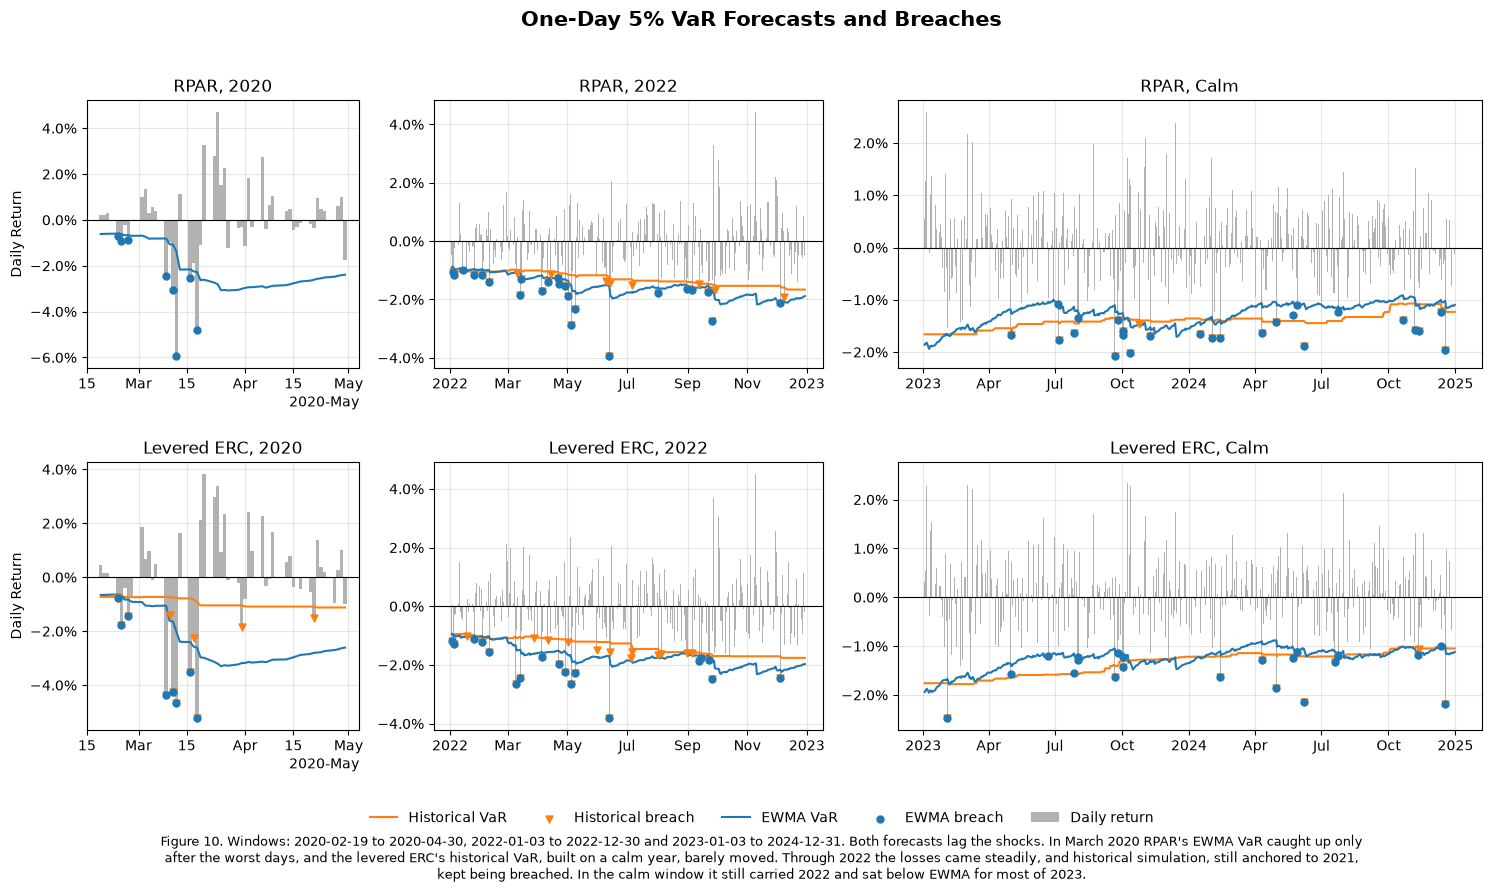

In [150]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 3, figsize = (18, 9), gridspec_kw = {"width_ratios": [1.4, 2, 3]})

method_colors = {"Historical": "tab:orange", "EWMA": "tab:blue"}

for row, series in zip(axes, ["RPAR", "Levered ERC"]):
    for ax, (label, (start, end)) in zip(row, VAR_WINDOWS.items()):
        window_returns = var_returns.loc[start:end, series]
        ax.bar(window_returns.index, window_returns, color = "gray", width = 1.0, alpha = 0.6, label = "Daily return")

        for method, color in method_colors.items():
            forecast = var_forecasts.loc[start:end, (series, method)]
            if forecast.notna().any():
                ax.plot(forecast.index, forecast, color = color, linewidth = 1.5, label = f"{method} VaR")
                breach_days = window_returns[window_returns < forecast]
                ax.scatter(breach_days.index, breach_days, color = color, s = 25, zorder = 3, marker = "v" if method == "Historical" else "o",
                           label = f"{method} breach")

        ax.set(title = f"{series}, {label}", ylabel = "Daily Return" if ax is row[0] else "")
        ax.axhline(0, color = "black", linewidth = 0.8)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
        ax.grid(alpha = 0.3)

handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.06), frameon = False)

fig.suptitle("One-Day 5% VaR Forecasts and Breaches", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 10. Windows: 2020-02-19 to 2020-04-30, 2022-01-03 to 2022-12-30 and 2023-01-03 to 2024-12-31. Both forecasts lag the shocks. In March 2020 RPAR's EWMA VaR caught up only\n"
         "after the worst days, and the levered ERC's historical VaR, built on a calm year, barely moved. Through 2022 the losses came steadily, and historical simulation, still anchored to 2021,\n"
         "kept being breached. In the calm window it still carried 2022 and sat below EWMA for most of 2023.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.18, hspace = 0.35, wspace = 0.18)
plt.show()

> **Method**
>
> VaR uses total returns, as the Notes require. Both forecasts for day $t$ use returns through $t-1$, and each series uses only its own history. The levered ERC therefore starts from its first return in 4.3 (2008-02-01), not from when its ETFs start.
>
> * **Historical simulation:** the empirical 5% quantile of the trailing 252 returns, interpolated linearly as in Section 1.
> * **Normal EWMA:** zero mean, $\sigma_t^2 = 0.97\,\sigma_{t-1}^2 + 0.03\,r_{t-1}^2$, seeded with the variance of the first 21 returns, and $\text{VaR}_t = -1.645\,\sigma_t$.
>
> A breach is a day whose return falls below the forecast. At a 5% rate we would expect about 2.6 breaches in the 51-day 2020 window, 12.6 in the 251-day 2022 window and 25 in the 502-day calm window.
>
> **Blanks.** `RPAR` (first return 2019-12-16) and `DBMF` (2019-05-09) have no historical-simulation forecast until 2020-12-15 and 2020-05-08. Both dates fall after the extended 2020 window closes, so their 2020 historical cells are blank (—). That means no forecast, not zero breaches. Every other cell has a forecast on every day of its window.
>
> **Breach rates**
>
> * **Full sample:** both methods are close to 5% for every series (4.6% to 6.1%). On average the forecasts are calibrated; the failures come in the episodes.
> * **2020:** every forecast failed.
>   * Historical simulation breached on 23.5% to 29.4% of days for the levered ERC, 60/40 and `NTSX` (12 to 15 breaches against 2.6 expected). Its VaR was built on the calm year before and barely moved.
>   * EWMA did better but still breached on 11.8% to 17.6% of days. `RPAR`'s eight breaches (15.7%) came in late February and from March 9 to 18, before the variance caught up (Figure 10). After March 18, its VaR of about −3% covered every loss.
> * **2022:** historical simulation breached on 11.6% to 12.0% of days for every series except `DBMF` (5.6%), more than twice the target.
>   * EWMA came closer for 60/40 (6.8%), the levered ERC (7.2%) and `NTSX` (8.0%).
>   * `RPAR` was the worst EWMA case, at 9.2% (23 breaches against 12.6 expected).
>   * `DBMF`, which gained in 2022, breached on only 3.2% of days.
> * **Calm:** every rate is at or below 5.4%. Historical simulation breached less than EWMA for every series except `NTSX` (4.2% against 4.0%), most clearly for the levered ERC (2.4%) and 60/40 (3.4%), because through 2023 its window still held 2022's losses, while EWMA had already adjusted to lower volatility.
>
> EWMA adapts faster than historical simulation, so it breached less in both episodes and more in the calm one. Neither kept up with a jump like March 2020. 2022 failed differently: it had no single shock, just a year of high volatility and steady losses. A forecast built on calm 2021 kept underestimating those losses, and for `RPAR` even the faster EWMA did.

## 5.2

On the breach days of the Normal EWMA ($\lambda = 0.97$) forecast within the extended 2020 and 2022 windows, report for each series

* the number of breaches
* the mean realized loss beside the mean CVaR forecast on those days
* the worst day's return as a multiple of the VaR forecast made for that day


In [151]:
#Normal EWMA VaR and CVaR forecasts for every day, from the volatility forecasts in 5.1
ewma_var, ewma_cvar = project_utils.normal_var_cvar(ewma_vols, level = VAR_LEVEL)

breach_days = {}
for series in VAR_SERIES:
    for label in ["2020", "2022"]:
        start, end = VAR_WINDOWS[label]
        window = pd.DataFrame({"Return": var_returns.loc[start:end, series],
                               "VaR": ewma_var.loc[start:end, series],
                               "CVaR": ewma_cvar.loc[start:end, series]}).dropna()
        window = window[window["Return"] < window["VaR"]]
        worst = window["Return"].idxmin()

        breach_days[(series, label)] = {"Breaches": len(window),
                                        "Mean Return on Breach Days": window["Return"].mean(),
                                        "Mean CVaR Forecast": window["CVaR"].mean(),
                                        "Realized / CVaR": window["Return"].mean() / window["CVaR"].mean(),
                                        "Worst Day": worst,
                                        "Worst Return": window.loc[worst, "Return"],
                                        "VaR Forecast that Day": window.loc[worst, "VaR"],
                                        "Worst Return / VaR": window.loc[worst, "Return"] / window.loc[worst, "VaR"]}

breach_days = pd.DataFrame(breach_days).T.rename_axis(["Series", "Episode"])
breach_days = breach_days.swaplevel().sort_index(level = "Episode", sort_remaining = False).reindex(VAR_SERIES, level = "Series")

display(breach_days.style.format({"Breaches": "{:.0f}",
                                  "Mean Return on Breach Days": "{:.2%}",
                                  "Mean CVaR Forecast": "{:.2%}",
                                  "Realized / CVaR": "{:.2f}x",
                                  "Worst Day": format_date,
                                  "Worst Return": "{:.2%}",
                                  "VaR Forecast that Day": "{:.2%}",
                                  "Worst Return / VaR": "{:.2f}x"})
                     .set_caption("Normal EWMA (λ = 0.97) breach days, 2020-02-19 to 2020-04-30 and 2022-01-03 to 2022-12-30; expected breaches 2.6 and 12.6"))

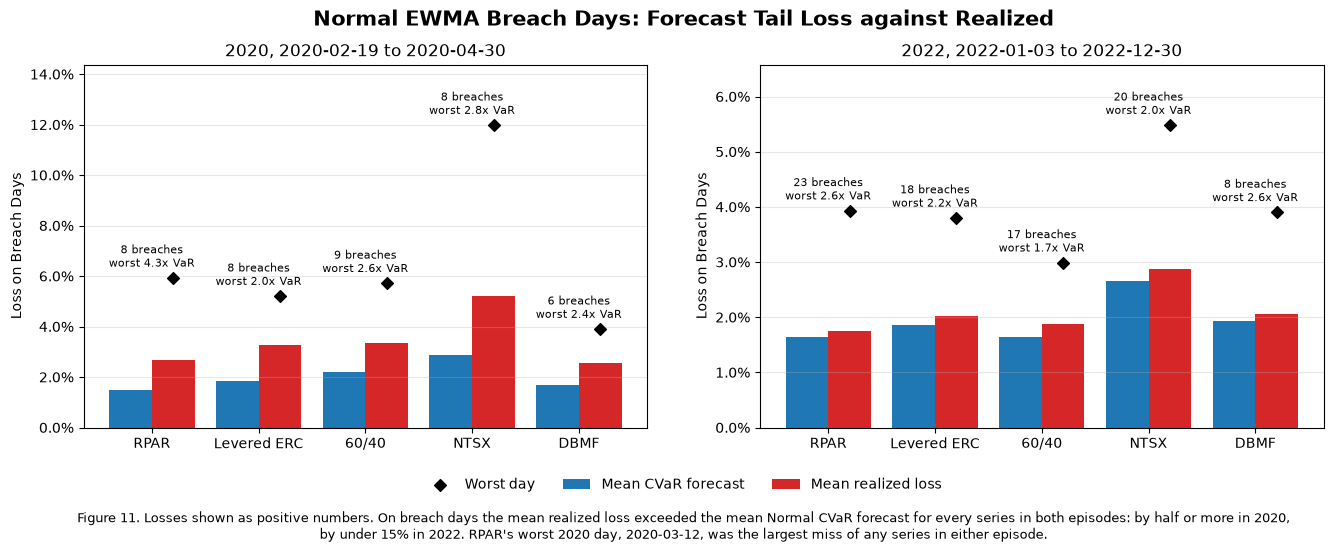

In [152]:
fig, axes = plt.subplots(1, 2, figsize = (16, 5.5))

for ax, label in zip(axes, ["2020", "2022"]):
    episode = breach_days.loc[label]
    x = np.arange(len(episode))

    ax.bar(x - 0.2, -episode["Mean CVaR Forecast"].astype(float), width = 0.4, color = "tab:blue", label = "Mean CVaR forecast")
    ax.bar(x + 0.2, -episode["Mean Return on Breach Days"].astype(float), width = 0.4, color = "tab:red", label = "Mean realized loss")
    ax.scatter(x + 0.2, -episode["Worst Return"].astype(float), marker = "D", color = "black", zorder = 3, label = "Worst day")

    for xi, (series, row) in zip(x, episode.iterrows()):
        ax.annotate(f"{row['Breaches']:.0f} breaches\nworst {row['Worst Return / VaR']:.1f}x VaR", (xi, -row["Worst Return"]), xytext = (0, 8),
                    textcoords = "offset points", ha = "center", fontsize = 8)

    ax.set(title = f"{label}, {VAR_WINDOWS[label][0]} to {VAR_WINDOWS[label][1]}", ylabel = "Loss on Breach Days")
    ax.set_xticks(x, episode.index)
    ax.set_ylim(0, -episode["Worst Return"].astype(float).min() * 1.2)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.08), frameon = False)

fig.suptitle("Normal EWMA Breach Days: Forecast Tail Loss against Realized", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 11. Losses shown as positive numbers. On breach days the mean realized loss exceeded the mean Normal CVaR forecast for every series in both episodes: by half or more in 2020,\n"
         "by under 15% in 2022. RPAR's worst 2020 day, 2020-03-12, was the largest miss of any series in either episode.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.22, wspace = 0.2)
plt.show()

> **Method**
>
> The Normal EWMA forecasts are the ones from 5.1. For a zero-mean Normal with forecast volatility $\sigma_t$, $\text{VaR}_t = -1.645\,\sigma_t$ and $\text{CVaR}_t = -\sigma_t\,\phi(1.645)/0.05 = -2.063\,\sigma_t$. The CVaR forecast is the loss the model expects on the days its VaR is breached, so on breach days it is the forecast to compare with the realized return. The windows are the extended ones: 2020-02-19 to 2020-04-30 (51 days, 2.6 breaches expected) and 2022-01-03 to 2022-12-30 (251 days, 12.6 expected). The worst day is the window's lowest return, which is a breach day for every series.
>
> **2020: too many breaches, and each too large**
>
> * **Number:** 6 to 9 breaches per series, two to three and a half times the 2.6 expected.
> * **Size:** on breach days the mean loss was 1.51x to 1.82x the mean CVaR forecast. For `RPAR` it was −2.66% against a forecast of −1.50%, a ratio of 1.77x.
> * **Worst day:** between 1.99x and 4.31x the VaR forecast for that day, so the Normal model missed the severity as well as the frequency. `RPAR` had the largest miss of any series in either episode: −5.93% on 2020-03-12 against a VaR of −1.38%, or 4.31x. Its forecast had only begun to rise (−0.62% on 2020-02-19), and under the model a loss that size is a 7σ day. On the same day 60/40 and `DBMF` had their worst days too, but at 2.59x and 2.36x VaR: `RPAR`'s loss was as large as 60/40's (−5.93% against −5.72%) while its forecast was much smaller (−1.38% against −2.21%). The levered ERC's and `NTSX`'s worst days came later (2020-03-18 and 2020-03-16), at 1.99x and 2.75x, after their forecasts had risen further.
>
> **2022: too many breaches, each about the right size**
>
> * **Number:** `RPAR` breached on 23 days, the most of any series and nearly twice the 12.6 expected. The levered ERC (18), 60/40 (17) and `NTSX` (20) also breached too often, while `DBMF` (8) breached too rarely.
> * **Size:** given a breach, the Normal tail was close. Mean realized losses were 1.06x to 1.14x the mean CVaR forecast (`RPAR`: −1.75% against −1.65%).
> * **Worst day:** 1.72x to 2.60x VaR. For four of the five series it was 2022-06-13, after the May CPI report, when stocks and bonds sold off together. `RPAR` lost 3.93% that day against a VaR of −1.54%, or 2.56x. `DBMF`'s worst day was 2022-11-10, the softer-than-expected CPI report, when the trends it was holding reversed.
>
> **What failed**
>
> In 2020 the problem was speed: volatility jumped within days, faster than an EWMA with $\lambda = 0.97$ can follow. Both the number of breaches and their size were too large, and `RPAR`'s low, stale forecast made its worst day the biggest miss in the table. In 2022 the size of each breach was roughly right, but there were too many of them. Losses kept clustering at a level the forecast treated as a 5% tail, and `RPAR` was hit most often.

## 5.3

Attribute each live fund's 2020 and 2022 episode to its factors day by day: each factor's excess return times the fund's full-sample daily beta from 2.2, summed over the episode by factor, beside the sum of the fund's daily excess returns. Do the same for the levered ERC portfolio with its actual daily weights and leverage.

* Report the attribution for each series and episode.
* Compute the static approximation, each beta times the factor's compounded total return over the window (episode-start weights for the ERC), and say what the gap between the two attributions contains.


In [153]:
ATTRIBUTION_WINDOWS = {"2020": ("2020-02-19", "2020-03-23"),
                       "2022": ("2022-01-03", "2022-10-24")}

daily_betas = factor_regressions.loc["Daily", FACTORS].astype(float)

#exposures held on each day of the window: constant full-sample betas for the funds, actual positions for the levered ERC
episode_exposures, episode_notes = {}, {}
for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    for fund in LIVE:
        days = excess_returns.loc[start:end, fund].dropna().index
        if days.empty:
            episode_notes[(label, fund)] = "no returns in the window"
            continue
        if days[0] > pd.Timestamp(start):
            episode_notes[(label, fund)] = f"from its first return, {days[0].date()}"
        episode_exposures[(label, fund)] = pd.DataFrame([daily_betas.loc[fund]] * len(days), index = days)

    episode_exposures[(label, "Levered ERC")] = levered_erc_positions.loc[start:end, FACTORS]

dynamic_attribution, static_attribution, attribution_gap = {}, {}, {}
for (label, series), exposure in episode_exposures.items():
    days = exposure.index
    factor_excess = excess_returns.loc[days, FACTORS]
    series_excess = levered_erc_excess.loc[days] if series == "Levered ERC" else excess_returns.loc[days, series]
    series_total = levered_erc_returns.loc[days] if series == "Levered ERC" else returns.loc[days, series]

    #day by day: exposure held that day times the factor's excess return, summed over the window
    dynamic = (exposure * factor_excess).sum()
    dynamic["Sum of Factors"] = dynamic[FACTORS].sum()
    dynamic["Excess Return (sum of daily)"] = series_excess.sum()
    dynamic["Residual"] = dynamic["Excess Return (sum of daily)"] - dynamic["Sum of Factors"]

    #the fund's residual split into its 2.2 intercept over the window's days and the rest
    intercept = 0.0 if series == "Levered ERC" else factor_regressions.loc[("Daily", series), "Annualized Intercept"] / 252 * len(days)
    dynamic["Intercept x Days"] = intercept
    dynamic["Unexplained"] = dynamic["Residual"] - intercept
    dynamic_attribution[(label, series)] = dynamic

    #static: the window's first exposure times the factor's compounded total return
    start_exposure = exposure.iloc[0]
    factor_compound = (1 + returns.loc[days, FACTORS]).prod() - 1
    static = start_exposure * factor_compound
    static["Sum of Factors"] = static[FACTORS].sum()
    static["Total Return (compounded)"] = (1 + series_total).prod() - 1
    static_attribution[(label, series)] = static

    #static minus dynamic, summed over factors, split exactly into three pieces
    attribution_gap[(label, series)] = {"Gap (static minus dynamic)": static["Sum of Factors"] - dynamic["Sum of Factors"],
                                        "Compounding": (start_exposure * (factor_compound - returns.loc[days, FACTORS].sum())).sum(),
                                        "Cash (exposure x SHV)": (start_exposure * returns.loc[days, "SHV"].sum()).sum(),
                                        "Weight Drift and Rebalancing": (start_exposure * factor_excess.sum() - (exposure * factor_excess).sum()).sum()}

attribution_names = ["Episode", "Series"]
dynamic_attribution = pd.DataFrame(dynamic_attribution).T.rename_axis(attribution_names)
static_attribution = pd.DataFrame(static_attribution).T.rename_axis(attribution_names)
attribution_gap = pd.DataFrame(attribution_gap).T.rename_axis(attribution_names)

for series_label, note in episode_notes.items():
    print(f"{series_label[0]}, {series_label[1]}: {note}")

display(dynamic_attribution.style.format("{:.2%}")
                           .set_caption("Day-by-day attribution: each factor's daily excess return times the full-sample daily beta (actual positions for the levered ERC), summed over the episode"))

display(static_attribution.style.format("{:.2%}")
                          .set_caption("Static approximation: each beta (episode-start position for the levered ERC) times the factor's compounded total return over the episode"))

display(attribution_gap.style.format("{:.2%}")
                       .set_caption("Static minus day-by-day attribution, summed over factors: compounding + cash + weight drift and rebalancing"))

2020, UPAR: no returns in the window
2020, ALLW: no returns in the window
2022, UPAR: from its first return, 2022-01-05
2022, ALLW: no returns in the window


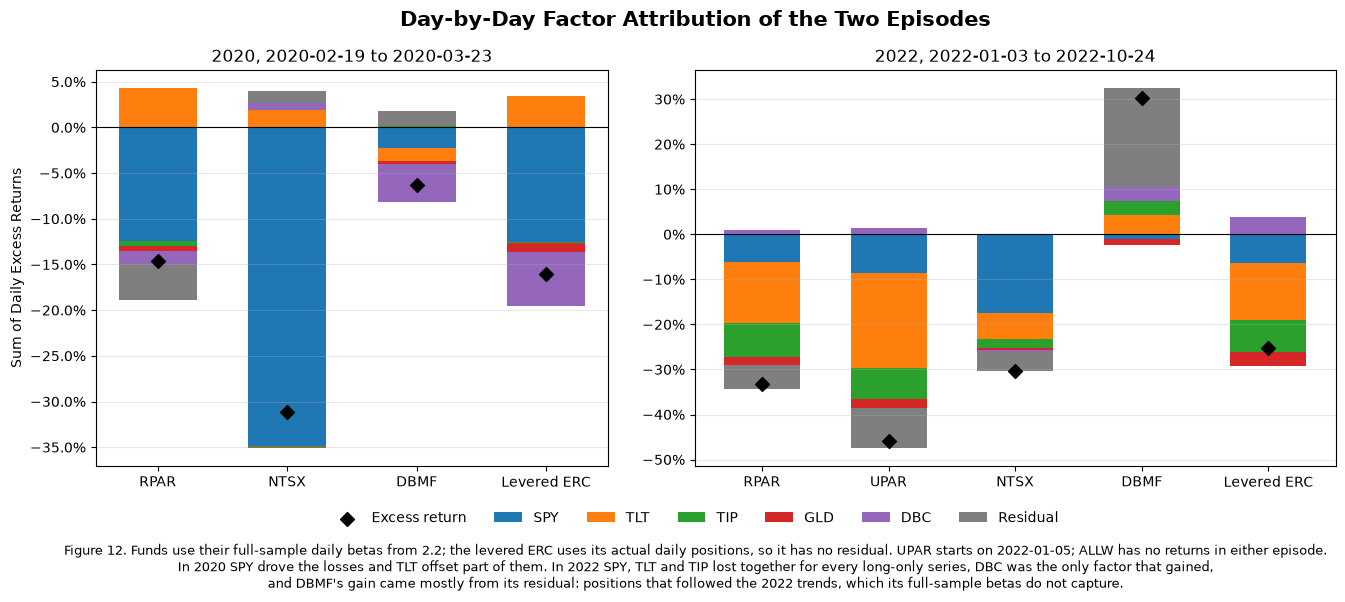

In [154]:
fig, axes = plt.subplots(1, 2, figsize = (16, 6), gridspec_kw = {"width_ratios": [4, 5]})

attribution_cols = FACTORS + ["Residual"]
attribution_colors = dict(zip(attribution_cols, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:gray"]))

for ax, label in zip(axes, ATTRIBUTION_WINDOWS):
    episode = dynamic_attribution.loc[label]

    #stack gains upward and losses downward from zero
    positive = np.zeros(len(episode))
    negative = np.zeros(len(episode))
    for col in attribution_cols:
        values = episode[col].to_numpy()
        ax.bar(episode.index, values, bottom = np.where(values >= 0, positive, negative), width = 0.6, color = attribution_colors[col], label = col)
        positive += np.clip(values, 0, None)
        negative += np.clip(values, None, 0)

    ax.scatter(episode.index, episode["Excess Return (sum of daily)"], marker = "D", s = 50, color = "black", zorder = 3, label = "Excess return")

    start, end = ATTRIBUTION_WINDOWS[label]
    ax.set(title = f"{label}, {start} to {end}", ylabel = "Sum of Daily Excess Returns" if ax is axes[0] else "")
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.1), frameon = False)

fig.suptitle("Day-by-Day Factor Attribution of the Two Episodes", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 12. Funds use their full-sample daily betas from 2.2; the levered ERC uses its actual daily positions, so it has no residual. UPAR starts on 2022-01-05; ALLW has no returns in either episode.\n"
         "In 2020 SPY drove the losses and TLT offset part of them. In 2022 SPY, TLT and TIP lost together for every long-only series, DBC was the only factor that gained,\n"
         "and DBMF's gain came mostly from its residual: positions that followed the 2022 trends, which its full-sample betas do not capture.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.22, wspace = 0.15)
plt.show()

> **Method**
>
> The episodes are the short windows: 2020-02-19 to 2020-03-23 (24 days) and 2022-01-03 to 2022-10-24 (204 days).
>
> * **Funds:** factor $k$'s contribution is $\beta_k \sum_t (r_{k,t} - r^f_t)$, with $\beta_k$ the fund's full-sample daily beta from 2.2. The residual is the fund's summed daily excess return minus the factor total. I split it into the fund's 2.2 intercept times the number of days and an unexplained remainder.
> * **Levered ERC:** each day's contribution is the position held at the start of that day (drifted weight times leverage, reset at each month-end) times the asset's excess return. Its cash earns `SHV`, so this attribution is exact and has no residual.
> * **Coverage:** `UPAR` has no 2020 episode and starts its 2022 episode on 2022-01-05. `ALLW` has no returns in either episode.
>
> **2020: an equity shock**
>
> * **`RPAR`:** −14.6% in summed daily excess return. `SPY` contributed −12.4%, `TLT` offset +4.3%, and `DBC`, `GLD` and `TIP` took another −2.5%.
>   * Its factors explain only −10.6%. The other −4.0% is a residual, almost none of which is the usual intercept drag (−0.3%).
>   * In this episode `RPAR` lost more than its betas imply. That fits its daily betas being understated (1.2 and 2.2: daily betas sum to 1.39, monthly ones to 1.53), which matters most when moves are large, and its commodity sleeve of producer equities falling with stocks (3.3).
> * **Levered ERC:** −16.1%, with the same `SPY` (−12.5%) and `TLT` (+3.5%) contributions. It held far more broad commodities, though, and `DBC` cost it −6.0% against −1.4% for `RPAR`.
> * **Other series:** `NTSX` lost −31.1%, nearly all of it from `SPY` (−34.9%). `DBMF` lost −6.4%, mostly through `DBC` (−4.2%).
>
> **2022: a bond and inflation shock**
>
> * **`RPAR`:** −33.2%. Here the losses came from the bond side: `TLT` −13.4% and `TIP` −7.7%, with `SPY` −6.3% and `GLD` −1.7%. `DBC` (+1.1%) was the only offset.
>   * The residual is −5.2%: −2.9% is the intercept drag over 204 days, and −2.4% is unexplained.
> * **`UPAR`:** the same pattern scaled up, at −45.9%.
> * **Levered ERC:** lost less (−25.3%) with nearly the same bond losses (`TLT` −12.7%, `TIP` −7.0%). The 7.9-point difference from `RPAR` is mostly its larger `DBC` gain (+4.0% against +1.1%) and `RPAR`'s −5.2% residual.
> * **`NTSX`:** lost −30.4%, mainly through `SPY` (−17.5%).
> * **`DBMF`:** gained +30.2%, but its betas explain only +8.3%. The other +21.9% came from positions that followed the trends of 2022, which a full-sample beta cannot capture.
>
> **Static against day-by-day**
>
> The static approximation multiplies each beta (the episode-start position for the levered ERC) by the factor's compounded total return over the window. Static minus day-by-day, summed over factors, splits exactly into three pieces:
>
> 1. **Compounding:** $\beta \times$ (compounded total return − sum of daily total returns). A constant daily beta is a portfolio rebalanced every day; applying the beta to the compounded return treats the exposure as bought and held. Over large one-way moves the two differ: `TLT` summed −44.0% in 2022 but compounded to −36.6%, and `SPY` summed −37.7% in 2020 but compounded to −33.4%. This is the largest piece for every series: +1.1% for `RPAR` in 2020, +2.4% in 2022, and +3.7% for `NTSX` in 2020. It is negative only for `DBMF` in 2022 (−1.1%). Its betas on `TLT` and `TIP` are negative, and because the bond losses compounded to less than they summed to, its short exposure gained less in the static version.
> 2. **Cash:** $\beta \times$ the summed `SHV` return. The static version uses total returns, while the betas were fitted on excess returns. This is small (`SHV` returned 0.58% in the 2020 window and 0.19% in 2022) but scales with the sum of betas: +0.8% for `RPAR` in 2020, and zero for `DBMF`, whose betas nearly cancel.
> 3. **Weight drift and rebalancing (levered ERC only):** frozen episode-start positions against the positions actually held.
>    * **2020: −1.4%.** As `SPY` and `DBC` fell, their positions shrank, so the portfolio lost less than its starting positions would have.
>    * **2022: +1.0%.** Each month-end reset bought falling bonds back to target and restored the 1.55x leverage after losses, so it lost more than its starting positions would have.
>
> **What the gap contains, and what it doesn't.** The gap contains three things: the compounding of the factor returns, the cash return the static version leaves in, and, for the ERC, the trading that kept its exposures from drifting. It contains none of the fund's residual. Neither attribution explains `RPAR`'s −4.0% in 2020 or `DBMF`'s +21.9% in 2022. The static total is also smaller in magnitude than the day-by-day one in every case, so it understates how much of each move the factors explain. For example, it attributes −8.7% to `RPAR`'s factors in 2020 against −10.6% day by day.

## 5.4

Compare `RPAR` in 2020 and 2022 using the factor paths, the attribution in 5.3, the breach rates in 5.1 and 5.2, and the rolling sums of betas from 2.3. Explain the similarities and differences in at most half a page.


In [155]:
rpar_rolling = rolling_betas["RPAR"]

rpar_episodes = {}
for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    days = excess_returns.loc[start:end, "RPAR"].dropna().index
    factor_compound = (1 + returns.loc[days, FACTORS]).prod() - 1

    #trailing 252-day windows ending before the episode, inside it, and the first one ending after it
    before = rpar_rolling.loc[:pd.Timestamp(start) - pd.Timedelta(days = 1), "Sum of Betas"]
    during = rpar_rolling.loc[start:end, "Sum of Betas"]
    after = rpar_rolling.loc[pd.Timestamp(end) + pd.Timedelta(days = 1):, "Sum of Betas"]

    rpar_episodes[label] = {"Trading Days": len(days),
                            "RPAR Total Return": (1 + returns.loc[days, "RPAR"]).prod() - 1,
                            **{f"{factor} Total Return": factor_compound[factor] for factor in FACTORS},
                            "SPY-TLT Correlation": returns.loc[days, "SPY"].corr(returns.loc[days, "TLT"]),
                            "Sum of Factors (5.3)": dynamic_attribution.loc[(label, "RPAR"), "Sum of Factors"],
                            "Residual (5.3)": dynamic_attribution.loc[(label, "RPAR"), "Residual"],
                            "Historical Breach Rate (5.1)": breach_table.loc[("RPAR", "Historical"), (label, "Breach Rate")],
                            "EWMA Breach Rate (5.1)": breach_table.loc[("RPAR", "EWMA"), (label, "Breach Rate")],
                            "EWMA Realized / CVaR (5.2)": breach_days.loc[(label, "RPAR"), "Realized / CVaR"],
                            "EWMA Worst Return / VaR (5.2)": breach_days.loc[(label, "RPAR"), "Worst Return / VaR"],
                            "Sum of Betas, Last Window Before": before.iloc[-1] if len(before) else np.nan,
                            "Sum of Betas, Windows Ending Inside": f"{during.min():.2f} to {during.max():.2f}" if len(during) else "—",
                            "Sum of Betas, First Window After": after.iloc[0] if len(after) else np.nan}

rpar_episodes = pd.DataFrame(rpar_episodes)

pct_rows = ["RPAR Total Return"] + [f"{factor} Total Return" for factor in FACTORS] + ["Sum of Factors (5.3)", "Residual (5.3)", "Historical Breach Rate (5.1)", "EWMA Breach Rate (5.1)"]
ratio_rows = ["SPY-TLT Correlation", "EWMA Realized / CVaR (5.2)", "EWMA Worst Return / VaR (5.2)", "Sum of Betas, Last Window Before", "Sum of Betas, First Window After"]

display(rpar_episodes.style.format(lambda x: x if isinstance(x, str) else ("—" if pd.isna(x) else f"{x:.0f}"))
                     .format(lambda x: "—" if pd.isna(x) else f"{x:.1%}", subset = (pct_rows, slice(None)))
                     .format(lambda x: "—" if pd.isna(x) else f"{x:.2f}", subset = (ratio_rows, slice(None)))
                     .set_caption("RPAR in the two episodes. Factor paths and attribution over the short windows; breach statistics over the extended windows (to 2020-04-30 and 2022-12-30)"))

print(f"First trailing 252-day RPAR regression ends {rpar_rolling.index[0].date()}; no window ends before the 2020 episode")

,2020,2022
Trading Days,24,204
RPAR Total Return,-13.6%,-28.8%
SPY Total Return,-33.4%,-19.3%
TLT Total Return,14.2%,-36.6%
TIP Total Return,-0.6%,-13.3%
GLD Total Return,-3.1%,-10.1%
DBC Total Return,-25.0%,20.1%
SPY-TLT Correlation,-0.50,0.02
Sum of Factors (5.3),-10.6%,-28.0%
Residual (5.3),-4.0%,-5.2%


First trailing 252-day RPAR regression ends 2020-12-14; no window ends before the 2020 episode


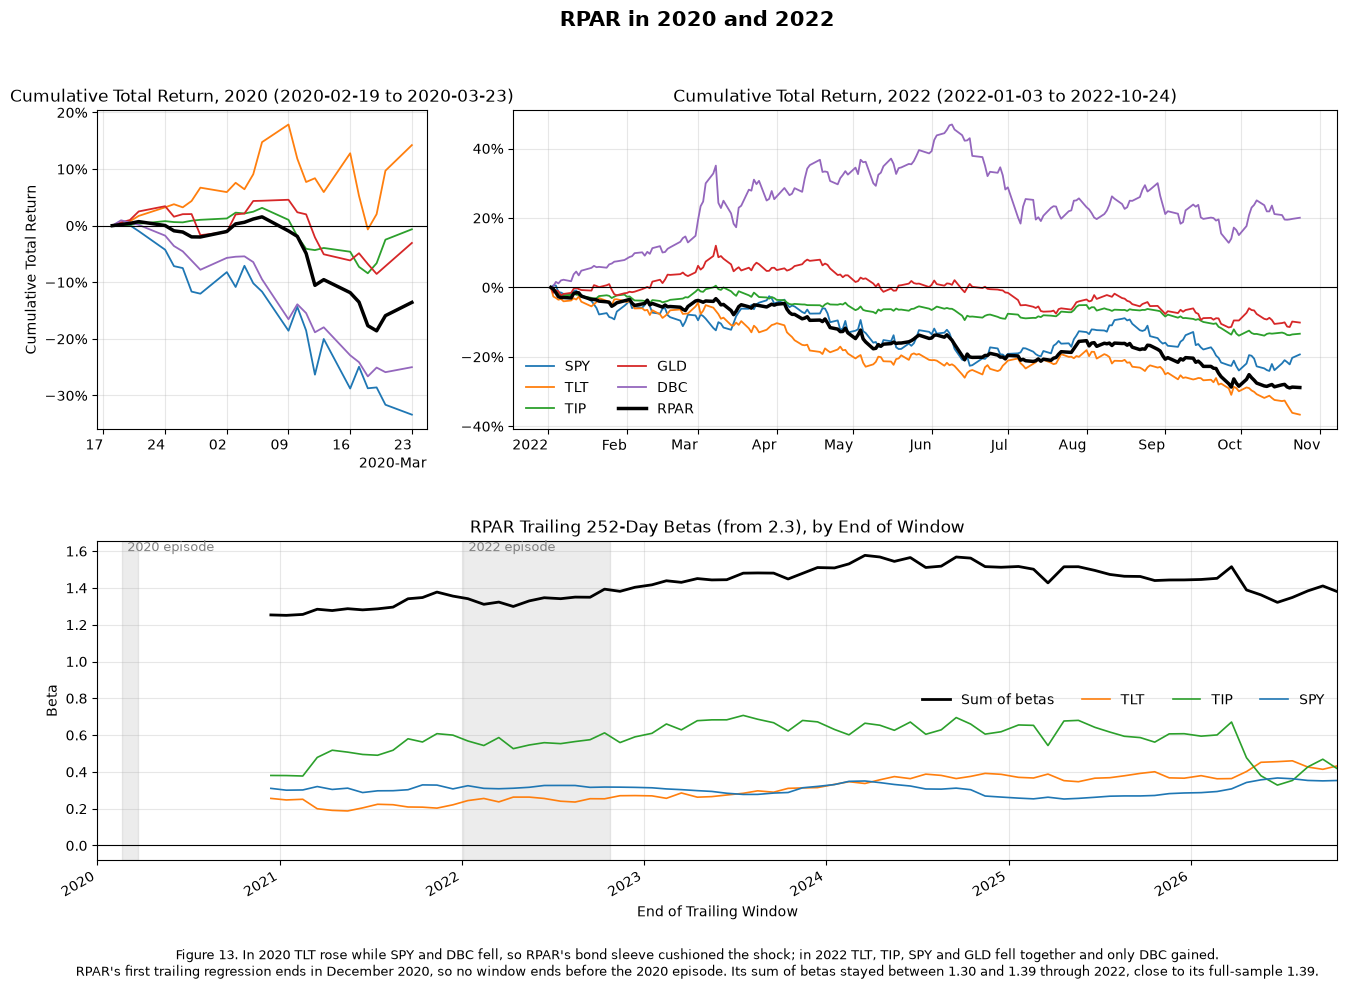

In [156]:
fig, axes = plt.subplot_mosaic([["2020", "2022"], ["betas", "betas"]], figsize = (16, 10), gridspec_kw = {"width_ratios": [1, 2.5]})

for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    ax = axes[label]
    days = returns.loc[start:end].index

    #growth of $1 from the close before the window, so every path starts at zero
    paths = (1 + returns.loc[days, FACTORS + ["RPAR"]]).cumprod() - 1
    paths = pd.concat([pd.DataFrame(0.0, index = [days[0] - pd.Timedelta(days = 1)], columns = paths.columns), paths])

    paths[FACTORS].plot(ax = ax, linewidth = 1.3, legend = False, x_compat = True)
    paths["RPAR"].plot(ax = ax, linewidth = 2.5, color = "black", legend = False, x_compat = True)

    ax.set(title = f"Cumulative Total Return, {label} ({start} to {end})", xlabel = "", ylabel = "Cumulative Total Return" if label == "2020" else "")
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    if label == "2020":
        ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday = mdates.MO))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.tick_params(axis = "x", labelrotation = 0)
    ax.grid(alpha = 0.3)

handles, labels = axes["2022"].get_legend_handles_labels()
axes["2022"].legend(handles, labels, frameon = False, loc = "lower left", ncol = 2)

ax = axes["betas"]
rpar_rolling["Sum of Betas"].plot(ax = ax, linewidth = 2, color = "black", label = "Sum of betas")
rpar_rolling[["TLT", "TIP", "SPY"]].plot(ax = ax, linewidth = 1.2, color = ["tab:orange", "tab:green", "tab:blue"])
for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color = "gray", alpha = 0.15)
    ax.annotate(f"{label} episode", (pd.Timestamp(start), 1.6), xytext = (4, 0), textcoords = "offset points", fontsize = 9, color = "gray")
ax.set(title = "RPAR Trailing 252-Day Betas (from 2.3), by End of Window", xlabel = "End of Trailing Window", ylabel = "Beta",
       xlim = (pd.Timestamp("2020-01-01"), rpar_rolling.index[-1]))
ax.axhline(0, color = "black", linewidth = 0.8)
ax.legend(frameon = False, ncol = 4, loc = "center right")
ax.grid(alpha = 0.3)

fig.suptitle("RPAR in 2020 and 2022", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 13. In 2020 TLT rose while SPY and DBC fell, so RPAR's bond sleeve cushioned the shock; in 2022 TLT, TIP, SPY and GLD fell together and only DBC gained.\n"
         "RPAR's first trailing regression ends in December 2020, so no window ends before the 2020 episode. Its sum of betas stayed between 1.30 and 1.39 through 2022, close to its full-sample 1.39.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.13, hspace = 0.35, wspace = 0.15)
plt.show()

> **Similarities.** Both episodes were large losses for `RPAR`: −13.6% in 24 days in 2020 and −28.8% in 204 days in 2022. In both, its factor exposures explain most of the loss (−10.6% and −28.0% of summed excess return), with a negative residual on top (−4.0% and −5.2%). Both broke the VaR forecasts. EWMA breached on 15.7% and 9.2% of days against 5%, and the worst days were 4.3x and 2.6x the VaR. Its exposure did not shift going into either episode. The sum of betas was 1.25 in the first trailing window (which contains March 2020) and 1.30 to 1.39 across windows before and inside 2022, close to the full-sample 1.39. So the losses came from what `RPAR` holds, not from a change in it.
>
> **Differences.**
>
> * **What fell.** 2020 was an equity and commodity shock in which bonds worked as a hedge: `SPY` −33%, `DBC` −25%, `TLT` +14%, with a daily `SPY`–`TLT` correlation of −0.50. `TLT` contributed +4.3% against `SPY`'s −12.4%. 2022 was a rate shock: `TLT` −37%, `TIP` −13%, `SPY` −19% and `GLD` −10%, with a `SPY`–`TLT` correlation of 0.02. Only `DBC` gained (+20%), and `RPAR`'s small `DBC` beta captured just +1.1% of it. The bond and TIPS sleeves, the largest because they are the least volatile, supplied 21 points of the loss. Risk parity relies on its sleeves being diversifiers, and that held in 2020 but failed in 2022.
> * **A jump against a grind.** In 2020 losses arrived faster than the forecasts could adapt: on breach days, realized losses were 1.77x the CVaR forecast. In 2022 the size of each breach was about right (1.06x CVaR), but there were too many of them (23 against 12.6 expected). Historical simulation, built on calm 2021, breached on 12% of days.
> * **The residual.** In 2020 almost all of it is unexplained (−3.7% against an intercept of −0.3%). That fits the understated daily betas and the commodity-equity sleeve found in earlier sections. In 2022 more than half is the steady intercept drag (−2.9%), the same shortfall 4.4 found against the levered ERC.
>
> 2020 tested whether `RPAR`'s diversification held in an equity crash, and it partly did. 2022 hit the scenario risk parity is most exposed to: stocks and bonds falling together while the largest weights sit in duration. The loss was twice as large, built up slowly, and came from the portfolio's holdings, not from forecasts reacting too slowly.

***


# 6. Regime Drivers


## 6.1

Choose two drivers from the list below. Construct each so that the value applied to month $t$ is known at the end of month $t-1$. Treat their relationships with returns as hypotheses to test.

* trailing stock-bond correlation of `SPY` and `TLT`, on a 12-month window of monthly returns and on a 63-day window of daily returns
* trailing 63-day realized volatility of `TLT`, annualized
* trailing 63-day realized volatility of `SPY`, annualized
* the three-month change in the 10-year zero-coupon yield on the `yields` sheet

For `RPAR` over its life, and for the levered ERC portfolio and 60/40 over the full backtest, report the annualized mean, volatility and Sharpe ratio of monthly excess returns within each tercile of the driver, or on each side of zero for a correlation. The yields end 2026-07-31, so the yield driver's last month is August 2026.


## 6.2

Which drivers separate good months from bad, for which strategies, and does the separation hold in both samples? Compare the two drivers in one concise interpretation, including both horizons if you chose stock-bond correlation.


***


# 7. The Allocation

Choose the evaluation criteria, cost assumptions, allocation rule, and comparison window. Different allocations and recommendations can be supported by the evidence; explain the choices that determine yours.


## 7.1

Before computing any Section 7 result, write a dated markdown cell stating

* at least three pass-fail criteria a strategy must meet for you to run it, each numeric and tied to a statistic from Sections 1 to 6
* a cost per unit of one-way turnover
* a borrowing spread over `SHV` on levered exposure

Give a source or a one-sentence rationale for each cost. Keep the original declaration. Record any revision in a second dated cell. The design uses evidence from the full history; Section 7 is a retrospective evaluation, not an untouched test.


## 7.2

Build one risk-balanced strategy you would run, from the asset-class ETFs and, if you choose, a sleeve of `DBMF` or another live fund. Any signal uses information available at the month-end before it acts. State the rule in full. Backtest it over the longest window the rule allows and report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, plus any other metric needed to apply your criteria
* one-way turnover per year
* returns gross and net of the costs declared in 7.1


## 7.3

Place your strategy beside `RPAR`, `ALLW`, `NTSX`, `DBMF`, the levered ERC portfolio from 4.3 and 60/40 on one common window you choose. Report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, net of your declared costs where leverage or turnover applies; add any metric needed for your criteria
* the pairwise correlations of daily returns on the common window


## 7.4

Judge three things separately: the allocation rule, `RPAR`'s implementation of it, and your own design. Apply the criteria from 7.1 and say which passed. Say how much weight `ALLW`'s record can carry given its length, and name one observable result over the next year that would reverse your recommendation. Half a page.


***


## Deliverables

Follow the [Project Guidelines](11.0.%20Project%20Guidelines.md).
